# Banking Customer & Loan Default Analysis (ML Project)

**Goal:** a bank has to decide *"will this applicant repay the loan?"* and also *"what kinds of customers do we have?"*.
This notebook answers both with machine learning, and prepares the data for a one-page **Power BI** dashboard.

**Dataset:** Credit Risk Dataset (Kaggle) - one row per loan applicant, 12 columns, target = `loan_status` (1 = defaulted, 0 = repaid).

| Part | What we do | ML type |
|---|---|---|
| 1 | Load and understand the data | - |
| 2 | **Data quality audit**: missing values, duplicates, impossible values | Preprocessing |
| 3 | **Cleaning**: duplicates, invalid values, imputation (5 methods compared), outliers, skew | Preprocessing |
| 4 | **Feature engineering** and encoding | Preprocessing |
| 5 | **EDA**: distributions, relationships, statistical tests | Analysis |
| 6 | **Customer segmentation** with K-Means | Unsupervised ML |
| 7 | **Loan default prediction**: imbalance, 3 models, tuning, thresholds, SHAP | Supervised ML |
| 8 | Score every customer and export files for Power BI | Deployment |

In [1]:
import warnings, os, json
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
os.makedirs("outputs/figures", exist_ok=True)

# ---- colour system: one validated categorical palette, used in a fixed order ----
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948")
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
NEUTRAL = "#c3c2b7"
CLASS_COLORS = {0: C["blue"], 1: C["orange"]}          # 0 = repaid, 1 = default
DIVERGING = LinearSegmentedColormap.from_list("div", [C["blue"], "#f0efec", C["red"]])
SEQ_BLUE = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#6da7ec", "#256abf", "#0d366b"])

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.family": "sans-serif", "figure.dpi": 100, "legend.frameon": False,
    "axes.axisbelow": True,
})

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"outputs/figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

# running log of every preprocessing decision (exported at the end)
prep_log = []
def log(step, issue, rows, treatment):
    prep_log.append({"step": step, "issue": issue, "rows_affected": int(rows), "treatment": treatment})

## 1. Load and understand the data

| Column | Meaning | Type |
|---|---|---|
| `person_age` | Applicant age (years) | Discrete numeric |
| `person_income` | Annual income | Continuous numeric |
| `person_home_ownership` | RENT / OWN / MORTGAGE / OTHER | Categorical (nominal) |
| `person_emp_length` | Years in current job | Discrete numeric |
| `loan_intent` | Purpose of the loan | Categorical (nominal) |
| `loan_grade` | Lender's risk grade, A (best) to G (worst) | Categorical (ordinal) |
| `loan_amnt` | Loan amount | Continuous numeric |
| `loan_int_rate` | Interest rate (%) | Continuous numeric |
| `loan_status` | **Target**: 1 = default, 0 = repaid | Binary |
| `loan_percent_income` | Loan amount / income | Continuous numeric |
| `cb_person_default_on_file` | Has a past default on record (Y/N) | Binary categorical |
| `cb_person_cred_hist_length` | Credit history length (years) | Discrete numeric |

In [2]:
raw = pd.read_csv("data/credit_risk_dataset.csv")
df = raw.copy()
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (32580, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [3]:
variable_types = pd.DataFrame({
    "type": (["Continuous"] * 4 + ["Discrete numeric"] * 3 + ["Categorical (nominal)"] * 2
             + ["Categorical (ordinal)"] + ["Binary categorical"] + ["Target (binary)"]),
}, index=["person_income", "loan_amnt", "loan_int_rate", "loan_percent_income",
          "person_age", "person_emp_length", "cb_person_cred_hist_length",
          "person_home_ownership", "loan_intent", "loan_grade",
          "cb_person_default_on_file", "loan_status"])
variable_types["distinct_values"] = df[variable_types.index].nunique()
variable_types["pandas_dtype"] = df[variable_types.index].dtypes.astype(str)
variable_types

,type,distinct_values,pandas_dtype
person_income,Continuous,4294,int64
loan_amnt,Continuous,753,int64
loan_int_rate,Continuous,348,float64
loan_percent_income,Continuous,77,float64
person_age,Discrete numeric,58,int64
person_emp_length,Discrete numeric,36,float64
cb_person_cred_hist_length,Discrete numeric,29,int64
person_home_ownership,Categorical (nominal),4,str
loan_intent,Categorical (nominal),6,str
loan_grade,Categorical (ordinal),7,str


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
person_age,32580.0,27.73,6.32,20.00,23.00,26.00,30.00,144.00
person_income,32580.0,65892.71,52547.02,4000.00,38500.00,55000.00,79200.00,2039784.00
person_emp_length,31685.0,4.79,4.14,0.00,2.00,4.00,7.00,123.00
loan_amnt,32580.0,9589.51,6322.13,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29464.0,11.01,3.24,5.42,7.90,10.99,13.47,23.22
loan_status,32580.0,0.22,0.41,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32580.0,0.17,0.11,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32580.0,5.80,4.05,2.00,3.00,4.00,8.00,30.00


## 2. Data quality audit

Before changing anything we measure what is wrong. We check four things:
**missing values, duplicate rows, impossible values, and outliers** (outliers come in step 3.4).

In [5]:
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "distinct": df.nunique(),
})
audit

,dtype,missing,missing_%,distinct
person_age,int64,0,0.00,58
person_income,int64,0,0.00,4294
person_home_ownership,str,0,0.00,4
person_emp_length,float64,895,2.75,36
loan_intent,str,0,0.00,6
loan_grade,str,0,0.00,7
loan_amnt,int64,0,0.00,753
loan_int_rate,float64,3116,9.56,348
loan_status,int64,0,0.00,2
loan_percent_income,float64,0,0.00,77


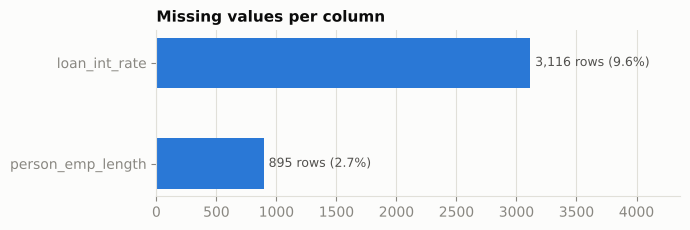

In [6]:
miss = df.isna().sum()
miss = miss[miss > 0].sort_values()
fig, ax = plt.subplots(figsize=(7, 2.4))
ax.barh(miss.index, miss.values, color=C["blue"], height=0.5)
for y, v in enumerate(miss.values):
    ax.text(v + 40, y, f"{v:,} rows ({v / len(df) * 100:.1f}%)", va="center", color=INK2, fontsize=9)
ax.set_xlim(0, miss.max() * 1.4)
ax.set_title("Missing values per column")
ax.grid(axis="y", visible=False)
savefig("01_missing_values")

In [7]:
print("Exact duplicate rows:", df.duplicated().sum())

impossible = pd.Series({
    "Age above 100": (df.person_age > 100).sum(),
    "Employment length above 60 years": (df.person_emp_length > 60).sum(),
    "Started working before age 14 (emp_length > age - 14)": (df.person_emp_length > df.person_age - 14).sum(),
    "Credit history longer than adult life (cred_hist > age - 16)": (df.cb_person_cred_hist_length > df.person_age - 16).sum(),
    "Income <= 0": (df.person_income <= 0).sum(),
    "Loan amount <= 0": (df.loan_amnt <= 0).sum(),
    "Loan is more than 100% of income": (df.loan_percent_income > 1).sum(),
    "Interest rate outside 0-40%": ((df.loan_int_rate < 0) | (df.loan_int_rate > 40)).sum(),
}, name="rows").to_frame()
impossible

Exact duplicate rows: 165


,rows
Age above 100,4
Employment length above 60 years,2
Started working before age 14 (emp_length > age - 14),2
Credit history longer than adult life (cred_hist > age - 16),0
Income <= 0,0
Loan amount <= 0,0
Loan is more than 100% of income,0
Interest rate outside 0-40%,0


**What the audit found**

- **Missing values** in `person_emp_length` and `loan_int_rate`.
- **Duplicate rows** (same applicant recorded twice).
- **Impossible values**: ages above 100, and employment lengths of 123 years.
- The other checks come back clean, so no action is needed there.

## 3. Data cleaning

> **A note on leakage.** Every cleaning step below uses only the *features*, never the target `loan_status`.
> So doing them before the train/test split does not leak the answer into the model. Steps that learn from
> the target-labelled training data (scaling, encoding, resampling) are done later *inside* the model pipeline.

### 3.1 Duplicates

In [8]:
n_dups = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
log("3.1 Duplicates", "Exact duplicate rows", n_dups, "Dropped (kept first occurrence)")
print(f"Removed {n_dups} duplicate rows -> {len(df):,} rows remain")

Removed 165 duplicate rows -> 32,415 rows remain


### 3.2 Impossible values

Two different rules, because the problems are different:

- **Age above 100** - the whole record is unreliable, so we **drop the row**.
- **Employment length longer than the person's working life** (`emp_length > age - 14`) - only that one cell is wrong,
  so we **set it to missing** and let the imputation step in 3.3 fill it in properly.

In [9]:
bad_age = df.person_age > 100
print("Rows with age > 100:")
display(df.loc[bad_age, ["person_age", "person_income", "person_emp_length", "loan_status"]])
log("3.2 Impossible values", "Age above 100", bad_age.sum(), "Rows dropped")
df = df.loc[~bad_age].reset_index(drop=True)

bad_emp = df.person_emp_length > (df.person_age - 14)
print("Rows with employment length longer than working life:")
display(df.loc[bad_emp, ["person_age", "person_emp_length", "person_income"]])
df.loc[bad_emp, "person_emp_length"] = np.nan
log("3.2 Impossible values", "Employment length > age - 14 (e.g. 123 years)", bad_emp.sum(),
    "Set to missing, then imputed in 3.3")

bad_hist = (df.cb_person_cred_hist_length > df.person_age - 16).sum()
print(f"Credit-history check (history longer than age - 16): {bad_hist} rows -> nothing to fix")
print(f"Rows now: {len(df):,}")

Rows with age > 100:


,person_age,person_income,person_emp_length,loan_status
81,144,250000,4.0,0
183,144,200000,4.0,0
575,123,80004,2.0,0
747,123,78000,7.0,0


Rows with employment length longer than working life:


,person_age,person_emp_length,person_income
0,22,123.0,59000
208,21,123.0,192000


Credit-history check (history longer than age - 16): 0 rows -> nothing to fix
Rows now: 32,411


### 3.3 Missing values

Not all missing data is the same. First question: **does the fact that a value is missing tell us something?**
We compare the default rate of rows with a missing value against rows with a value present, and test the difference.

In [10]:
rows = []
for col in ["person_emp_length", "loan_int_rate"]:
    flag = df[col].isna()
    ct = pd.crosstab(flag, df.loan_status)
    chi2, p, _, _ = stats.chi2_contingency(ct)
    rows.append({"column": col, "missing_rows": int(flag.sum()), "missing_%": round(flag.mean() * 100, 2),
                 "default_rate_if_missing": f"{df.loc[flag, 'loan_status'].mean():.1%}",
                 "default_rate_if_present": f"{df.loc[~flag, 'loan_status'].mean():.1%}",
                 "chi2_p_value": f"{p:.4g}"})
pd.DataFrame(rows).set_index("column")

,missing_rows,missing_%,default_rate_if_missing,default_rate_if_present,chi2_p_value
column,,,,,
person_emp_length,889,2.74,31.7%,21.6%,7.947e-13
loan_int_rate,3094,9.55,20.7%,22.0%,0.1072


**Reading the result**

- `loan_int_rate`: missing rows default at about the same rate as the rest, so the missingness looks **random**.
  Plain imputation is safe.
- `person_emp_length`: missing rows default **noticeably more often** (and the p-value confirms it is not chance).
  So the *fact that it is missing* is itself a useful signal. We therefore keep a **missing-indicator column**
  (`emp_length_missing`) in addition to imputing the value.

**Which imputation method?** Instead of guessing, we run a fair test: take rows where the value is known,
hide 15% of them, let each method fill them back in, and measure the error against the true values.
Five methods compete: mean, median, group median, KNN, and iterative (regression-based) imputation.

In [11]:
from sklearn.experimental import enable_iterative_imputer  # noqa: F401  (must come first)
from sklearn.impute import KNNImputer, IterativeImputer
from sklearn.linear_model import BayesianRidge

# missing indicator BEFORE imputing (keeps the information that the value was missing)
df["emp_length_missing"] = df.person_emp_length.isna().astype(int)
log("3.3 Missing values", "person_emp_length missing or invalid -> indicator column", df.emp_length_missing.sum(),
    "Added emp_length_missing flag (missingness is linked to default)")

# helper columns the imputers may use (all complete, none uses the target)
df["grade_num"] = df.loan_grade.map({g: i + 1 for i, g in enumerate("ABCDEFG")})
df["person_income_log"] = np.log1p(df.person_income)
helpers = ["person_age", "person_income_log", "loan_amnt", "loan_percent_income",
           "cb_person_cred_hist_length", "grade_num"]

def impute_column(frame, col, strategy, helpers, group_col=None):
    '''Return a copy of frame[col] with the NaNs filled using the chosen strategy.'''
    s = frame[col].copy()
    miss = s.isna()
    if strategy == "mean":
        s[miss] = s.mean()
    elif strategy == "median":
        s[miss] = s.median()
    elif strategy == "group_median":
        gm = frame.groupby(group_col)[col].transform("median")
        s[miss] = gm[miss]
        s = s.fillna(s.median())
    elif strategy in ("knn", "iterative"):
        X = frame[helpers + [col]].astype(float)
        if strategy == "knn":
            mu, sd = X.mean(), X.std()
            arr = KNNImputer(n_neighbors=5).fit_transform((X - mu) / sd)
            out = arr[:, -1] * sd[col] + mu[col]
        else:
            arr = IterativeImputer(estimator=BayesianRidge(), max_iter=10,
                                   random_state=RANDOM_STATE).fit_transform(X)
            out = arr[:, -1]
        s[miss] = out[miss.values]
    return s

def compare_imputers(frame, col, helpers, group_col, frac=0.15, n=6000):
    base = (frame.dropna(subset=[col] + helpers + [group_col])
                 .sample(n, random_state=RANDOM_STATE).reset_index(drop=True))
    rng = np.random.default_rng(RANDOM_STATE)
    mask = rng.random(len(base)) < frac
    truth = base.loc[mask, col].values
    masked = base.copy()
    masked.loc[mask, col] = np.nan
    rows = []
    for strat in ["mean", "median", "group_median", "knn", "iterative"]:
        pred = impute_column(masked, col, strat, helpers, group_col).loc[mask].values
        rows.append((strat, np.sqrt(np.mean((pred - truth) ** 2)), np.mean(np.abs(pred - truth))))
    return pd.DataFrame(rows, columns=["strategy", "RMSE", "MAE"]).set_index("strategy").sort_values("RMSE")

cmp_rate = compare_imputers(df, "loan_int_rate", helpers, group_col="loan_grade")
cmp_emp = compare_imputers(df, "person_emp_length", helpers, group_col="person_home_ownership")
print("loan_int_rate  (group median = median within each loan grade)")
display(cmp_rate.round(3))
print("person_emp_length  (group median = median within each home-ownership group)")
display(cmp_emp.round(3))

loan_int_rate  (group median = median within each loan grade)


,RMSE,MAE
strategy,,
group_median,0.986,0.765
knn,1.088,0.852
iterative,1.143,0.886
median,3.263,2.731
mean,3.263,2.732


person_emp_length  (group median = median within each home-ownership group)


,RMSE,MAE
strategy,,
iterative,3.799,2.987
group_median,3.954,2.881
mean,3.966,3.058
median,4.065,3.026
knn,4.121,3.208


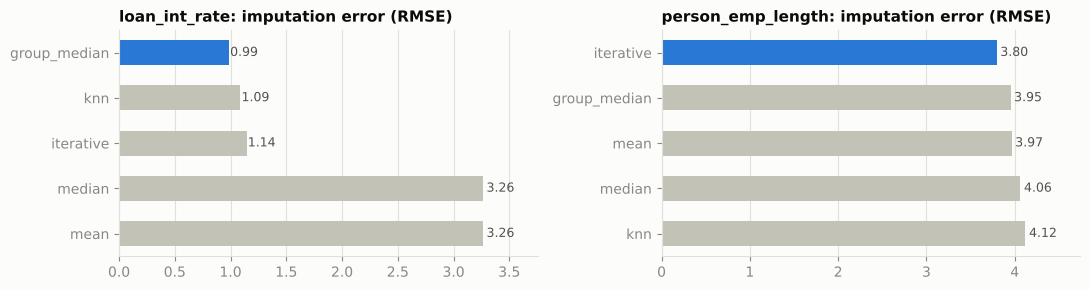

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, (title, res) in zip(axes, [("loan_int_rate: imputation error (RMSE)", cmp_rate),
                                   ("person_emp_length: imputation error (RMSE)", cmp_emp)]):
    res = res.sort_values("RMSE", ascending=False)
    colors = [NEUTRAL] * (len(res) - 1) + [C["blue"]]
    ax.barh(res.index, res["RMSE"], color=colors, height=0.55)
    for y, v in enumerate(res["RMSE"]):
        ax.text(v * 1.01, y, f"{v:.2f}", va="center", fontsize=9, color=INK2)
    ax.set_title(title)
    ax.set_xlim(0, res["RMSE"].max() * 1.15)
    ax.grid(axis="y", visible=False)
savefig("02_imputation_comparison")

In [13]:
best_rate = cmp_rate.index[0]
best_emp = cmp_emp.index[0]
print(f"Winner for loan_int_rate     : {best_rate}")
print(f"Winner for person_emp_length : {best_emp}")

df_pre_impute = df[["loan_int_rate", "person_emp_length"]].copy()

n_rate, n_emp = int(df.loan_int_rate.isna().sum()), int(df.person_emp_length.isna().sum())
df["loan_int_rate"] = impute_column(df, "loan_int_rate", best_rate, helpers, "loan_grade")
df["person_emp_length"] = impute_column(df, "person_emp_length", best_emp, helpers, "person_home_ownership")
log("3.3 Missing values", "loan_int_rate missing", n_rate, f"Imputed with {best_rate} (best of 5 on a masked test)")
log("3.3 Missing values", "person_emp_length missing", n_emp, f"Imputed with {best_emp} (best of 5 on a masked test)")

assert df.isna().sum().sum() == 0
print("Missing values left in the dataset:", int(df.isna().sum().sum()))

Winner for loan_int_rate     : group_median
Winner for person_emp_length : iterative
Missing values left in the dataset: 0


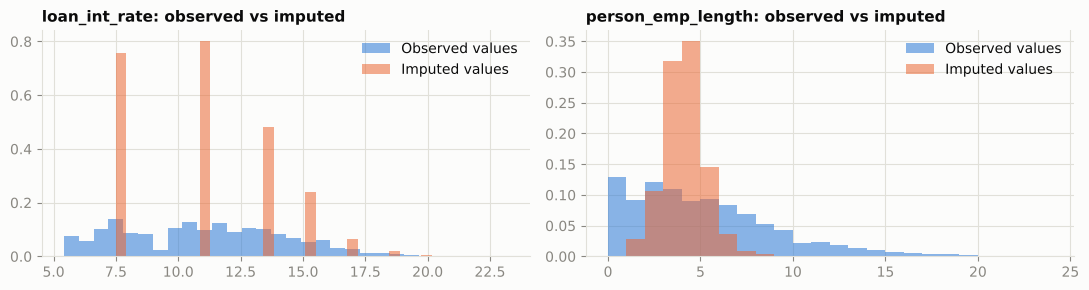

In [14]:
# Sanity check: imputed values should look like the real ones, not pile up on a single number
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, col in zip(axes, ["loan_int_rate", "person_emp_length"]):
    observed = df_pre_impute[col].dropna()
    imputed = df.loc[df_pre_impute[col].isna(), col]
    bins = 30 if col == "loan_int_rate" else np.arange(0, 25, 1)
    ax.hist(observed, bins=bins, density=True, alpha=0.55, color=C["blue"], label="Observed values")
    ax.hist(imputed, bins=bins, density=True, alpha=0.55, color=C["orange"], label="Imputed values")
    ax.set_title(f"{col}: observed vs imputed")
    ax.legend()
savefig("03_imputed_vs_observed")

### 3.4 Outliers

**Detect first** with two standard rules, then decide variable by variable:

- **IQR rule**: a value is an outlier if it lies more than 1.5 x IQR beyond the quartiles (Tukey fences).
- **Z-score rule**: a value is an outlier if it is more than 3 standard deviations from the mean.

In [15]:
out_cols = ["person_age", "person_income", "person_emp_length", "loan_amnt",
            "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length"]

def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

rows = []
for c in out_cols:
    lo, hi = iqr_bounds(df[c])
    z = np.abs(stats.zscore(df[c]))
    n_iqr = int(((df[c] < lo) | (df[c] > hi)).sum())
    rows.append({"column": c, "min": df[c].min(), "max": df[c].max(),
                 "IQR_lower": round(lo, 2), "IQR_upper": round(hi, 2),
                 "outliers_IQR": n_iqr, "outliers_IQR_%": round(n_iqr / len(df) * 100, 2),
                 "outliers_zscore>3": int((z > 3).sum()), "skewness": round(df[c].skew(), 2)})
outlier_table = pd.DataFrame(rows).set_index("column")
outlier_table

,min,max,IQR_lower,IQR_upper,outliers_IQR,outliers_IQR_%,outliers_zscore>3,skewness
column,,,,,,,,
person_age,20.00,94.00,12.50,40.50,1486,4.58,552,1.94
person_income,4000.00,2039784.00,-22550.00,140250.00,1475,4.55,353,9.78
person_emp_length,0.00,41.00,-5.50,14.50,850,2.62,447,1.27
loan_amnt,500.00,35000.00,-5875.00,23125.00,1679,5.18,336,1.19
loan_int_rate,5.42,23.22,-0.52,21.88,6,0.02,39,0.21
loan_percent_income,0.00,0.83,-0.12,0.44,650,2.01,335,1.06
cb_person_cred_hist_length,2.00,30.00,-4.50,15.50,1138,3.51,283,1.66


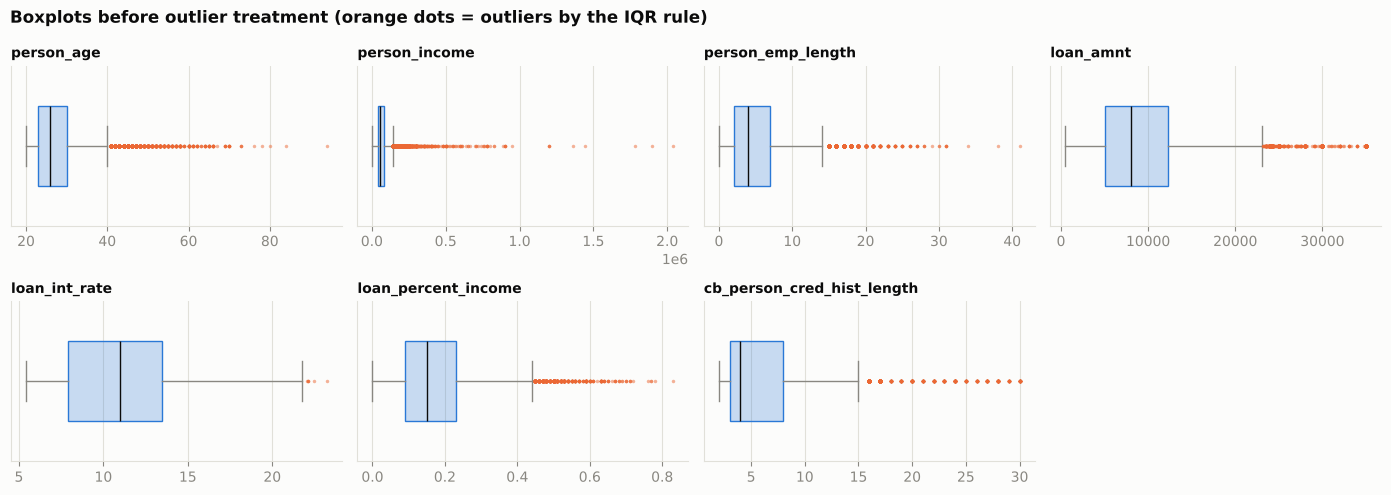

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(14, 5))
for ax, c in zip(axes.ravel(), out_cols):
    ax.boxplot(df[c], vert=False, widths=0.5, patch_artist=True,
               boxprops=dict(facecolor=C["blue"] + "40", edgecolor=C["blue"]),
               medianprops=dict(color=INK), whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED),
               flierprops=dict(marker="o", markersize=2.5, markerfacecolor=C["orange"],
                               markeredgecolor="none", alpha=0.5))
    ax.set_title(c, fontsize=10)
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
axes.ravel()[-1].axis("off")
fig.suptitle("Boxplots before outlier treatment (orange dots = outliers by the IQR rule)", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
savefig("04_outliers_before")

**Treatment decisions (different tool for each kind of variable)**

| Variable | Decision | Why |
|---|---|---|
| `person_income`, `loan_amnt` | **Winsorize** at the 1st and 99th percentile | Money amounts have a long right tail (income up to about 2 million). Capping keeps the row but stops a few extreme values from dominating. |
| `person_age`, `person_emp_length`, `cb_person_cred_hist_length` | **Cap at 3 x IQR** ("far-out" fences) | Real but extreme values. Only the most extreme are capped, so ordinary variation is left alone. |
| `loan_int_rate`, `loan_percent_income` | **Keep as they are** | They are bounded and valid. The "outliers" are genuinely risky borrowers, which is exactly the signal the model needs. |
| Skewed money columns | **Log transform** (3.5) | Makes distributions closer to symmetric for distance-based and linear methods. |

In [17]:
df_before_cap = df.copy()
caps = {}
for c in ["person_income", "loan_amnt"]:
    lo, hi = df[c].quantile([0.01, 0.99])
    caps[c] = (lo, hi, "winsorized at 1st/99th percentile")
for c in ["person_age", "person_emp_length", "cb_person_cred_hist_length"]:
    lo, hi = iqr_bounds(df[c], k=3.0)
    caps[c] = (lo, hi, "capped at 3 x IQR fence")

cap_rows = []
for c, (lo, hi, how) in caps.items():
    n_cap = int(((df[c] < lo) | (df[c] > hi)).sum())
    df[c] = df[c].clip(lo, hi)
    log("3.4 Outliers", f"{c} extreme values", n_cap, how)
    cap_rows.append({"column": c, "method": how, "lower": round(max(lo, df_before_cap[c].min()), 1),
                     "upper": round(hi, 1), "values_capped": n_cap,
                     "max_before": df_before_cap[c].max(), "max_after": df[c].max()})
pd.DataFrame(cap_rows).set_index("column")

,method,lower,upper,values_capped,max_before,max_after
column,,,,,,
person_income,winsorized at 1st/99th percentile,14400.0,225000.0,638,2039784.0,225000.0
loan_amnt,winsorized at 1st/99th percentile,1000.0,29800.0,335,35000.0,29800.0
person_age,capped at 3 x IQR fence,20.0,51.0,244,94.0,51.0
person_emp_length,capped at 3 x IQR fence,0.0,22.0,52,41.0,22.0
cb_person_cred_hist_length,capped at 3 x IQR fence,2.0,23.0,148,30.0,23.0


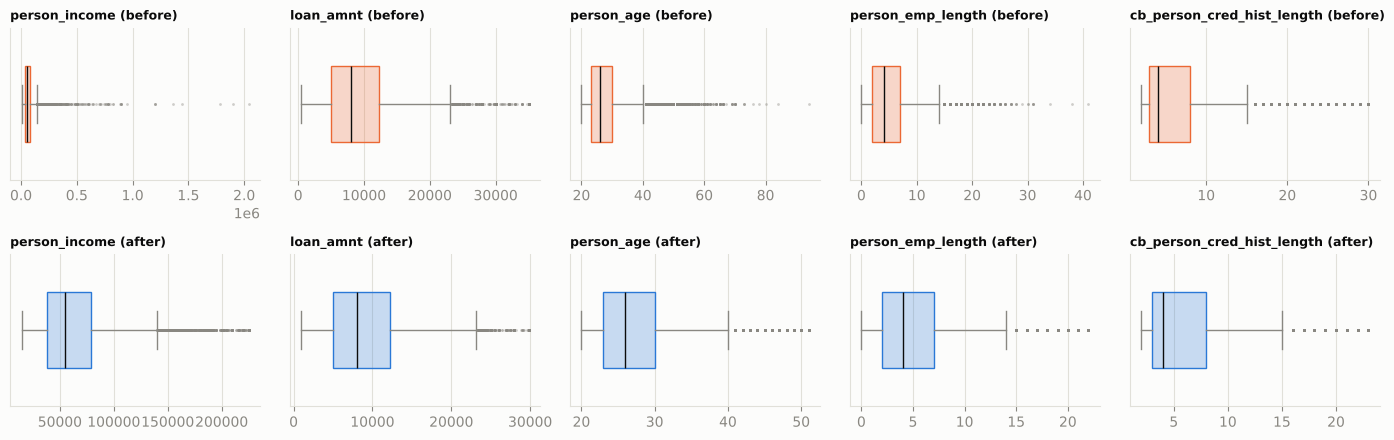

In [18]:
cols = list(caps.keys())
fig, axes = plt.subplots(2, len(cols), figsize=(14, 4.5))
for j, c in enumerate(cols):
    for i, (frame, label) in enumerate([(df_before_cap, "before"), (df, "after")]):
        ax = axes[i, j]
        ax.boxplot(frame[c], vert=False, widths=0.5, patch_artist=True,
                   boxprops=dict(facecolor=(C["orange"] if i == 0 else C["blue"]) + "40",
                                 edgecolor=C["orange"] if i == 0 else C["blue"]),
                   medianprops=dict(color=INK), whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED),
                   flierprops=dict(marker="o", markersize=2, markerfacecolor=MUTED, markeredgecolor="none", alpha=0.4))
        ax.set_yticks([]); ax.grid(axis="y", visible=False)
        ax.set_title(f"{c} ({label})", fontsize=9)
savefig("05_outliers_before_after")

### 3.5 Skewness: log transform

Income and loan amount are right-skewed. `log1p` compresses the long tail. We keep the original (capped) columns
for reporting and create log versions for the models.

In [19]:
df["person_income_log"] = np.log1p(df.person_income)      # recomputed after capping
df["loan_amnt_log"] = np.log1p(df.loan_amnt)

skew = pd.DataFrame({
    "skew_original": df_before_cap[["person_income", "loan_amnt"]].skew(),
    "skew_after_capping": df[["person_income", "loan_amnt"]].skew(),
}).round(2)
skew["skew_after_log"] = [round(df.person_income_log.skew(), 2), round(df.loan_amnt_log.skew(), 2)]
log("3.5 Skewness", "Right-skewed income and loan amount", len(df), "log1p transform -> person_income_log, loan_amnt_log")
skew

,skew_original,skew_after_capping,skew_after_log
person_income,9.78,1.72,0.03
loan_amnt,1.19,1.06,-0.46


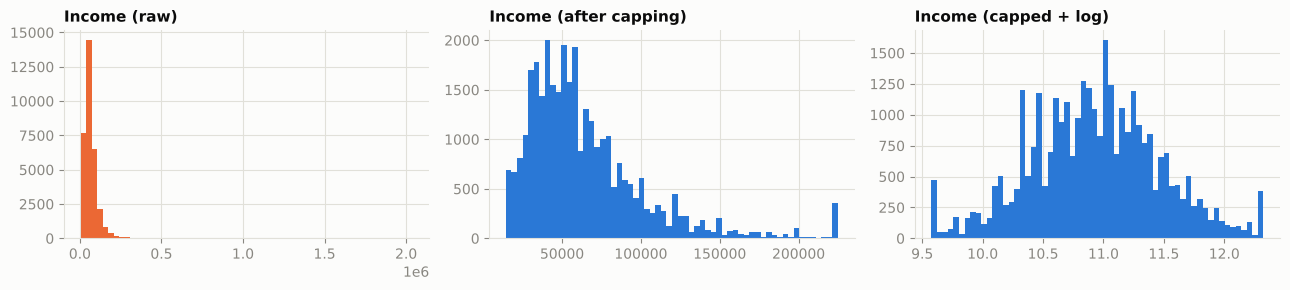

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
axes[0].hist(df_before_cap.person_income, bins=60, color=C["orange"]); axes[0].set_title("Income (raw)")
axes[1].hist(df.person_income, bins=60, color=C["blue"]); axes[1].set_title("Income (after capping)")
axes[2].hist(df.person_income_log, bins=60, color=C["blue"]); axes[2].set_title("Income (capped + log)")
savefig("06_income_skew_fix")

### 3.6 Cleaning summary

In [21]:
print(f"Original rows : {len(raw):,}")
print(f"Clean rows    : {len(df):,}  (removed {len(raw) - len(df)} = duplicates + impossible ages)")
print(f"Missing cells : {int(df.isna().sum().sum())}")
pd.DataFrame(prep_log)

Original rows : 32,580
Clean rows    : 32,411  (removed 169 = duplicates + impossible ages)
Missing cells : 0


,step,issue,rows_affected,treatment
0,3.1 Duplicates,Exact duplicate rows,165,Dropped (kept first occurrence)
1,3.2 Impossible values,Age above 100,4,Rows dropped
2,3.2 Impossible values,Employment length > age - 14 (e.g. 123 years),2,"Set to missing, then imputed in 3.3"
3,3.3 Missing values,person_emp_length missing or invalid -> indica...,889,Added emp_length_missing flag (missingness is ...
4,3.3 Missing values,loan_int_rate missing,3094,Imputed with group_median (best of 5 on a mask...
5,3.3 Missing values,person_emp_length missing,889,Imputed with iterative (best of 5 on a masked ...
6,3.4 Outliers,person_income extreme values,638,winsorized at 1st/99th percentile
7,3.4 Outliers,loan_amnt extreme values,335,winsorized at 1st/99th percentile
8,3.4 Outliers,person_age extreme values,244,capped at 3 x IQR fence
9,3.4 Outliers,person_emp_length extreme values,52,capped at 3 x IQR fence


## 4. Feature engineering and encoding

New columns that capture risk better than the raw ones, plus business-friendly bands used for EDA and the dashboard.

| New feature | Formula | Why it helps |
|---|---|---|
| `interest_burden` | loan amount x interest rate / income | Yearly interest cost as a share of income |
| `cred_hist_to_age` | credit history length / age | How much of adult life the customer has credit behind them |
| `emp_to_age` | employment length / age | Job stability relative to age |
| `default_on_file_num` | Y -> 1, N -> 0 | Binary encoding |
| `grade_num` | A..G -> 1..7 | **Ordinal encoding** (order matters, A is better than G) |

`person_home_ownership` and `loan_intent` have no natural order, so they are **one-hot encoded** inside the model
pipeline (section 7).

In [22]:
df["default_on_file_num"] = (df.cb_person_default_on_file == "Y").astype(int)
df["interest_burden"] = df.loan_amnt * df.loan_int_rate / 100 / df.person_income
df["cred_hist_to_age"] = df.cb_person_cred_hist_length / df.person_age
df["emp_to_age"] = df.person_emp_length / df.person_age

df["age_band"] = pd.cut(df.person_age, [0, 25, 30, 35, 45, 200],
                        labels=["25 and under", "26 to 30", "31 to 35", "36 to 45", "46 and over"])
df["income_band"] = pd.cut(df.person_income, [0, 30000, 50000, 75000, 100000, np.inf],
                           labels=["Under 30K", "30K to 50K", "50K to 75K", "75K to 100K", "100K and over"])
df["loan_amnt_band"] = pd.cut(df.loan_amnt, [0, 5000, 10000, 15000, 20000, np.inf],
                              labels=["Under 5K", "5K to 10K", "10K to 15K", "15K to 20K", "20K and over"])
df["dti_band"] = pd.cut(df.loan_percent_income, [-0.001, 0.10, 0.20, 0.30, 1.0],
                        labels=["Under 10%", "10% to 20%", "20% to 30%", "Over 30%"])
for b in ["age_band", "income_band", "loan_amnt_band", "dti_band"]:
    df[b] = df[b].astype(str)

df[["interest_burden", "cred_hist_to_age", "emp_to_age", "grade_num", "default_on_file_num",
    "age_band", "income_band", "loan_amnt_band", "dti_band"]].head()

,interest_burden,cred_hist_to_age,emp_to_age,grade_num,default_on_file_num,age_band,income_band,loan_amnt_band,dti_band
0,0.080915,0.136364,0.206191,4,1,25 and under,50K to 75K,20K and over,Over 30%
1,0.007736,0.095238,0.238095,2,0,25 and under,Under 30K,Under 5K,Under 10%
2,0.049156,0.120000,0.040000,3,0,25 and under,Under 30K,5K to 10K,Over 30%
3,0.069291,0.086957,0.173913,3,0,25 and under,50K to 75K,20K and over,Over 30%
4,0.078170,0.166667,0.333333,3,1,25 and under,50K to 75K,20K and over,Over 30%


## 5. Exploratory Data Analysis (EDA)

### 5.1 The target: how many customers default?

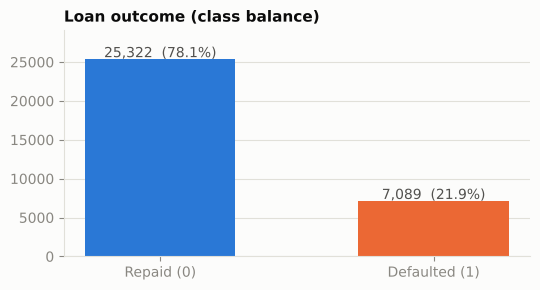

Imbalance ratio repaid : default = 3.6 : 1  -> handled in section 7


In [23]:
vc = df.loan_status.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5.5, 3))
bars = ax.bar(["Repaid (0)", "Defaulted (1)"], vc.values, color=[C["blue"], C["orange"]], width=0.55)
for b, v in zip(bars, vc.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 300, f"{v:,}  ({v / len(df):.1%})", ha="center", color=INK2)
ax.set_ylim(0, vc.max() * 1.15)
ax.set_title("Loan outcome (class balance)")
ax.grid(axis="x", visible=False)
savefig("07_target_distribution")
print(f"Imbalance ratio repaid : default = {vc[0] / vc[1]:.1f} : 1  -> handled in section 7")

### 5.2 Univariate: shape of each numeric variable

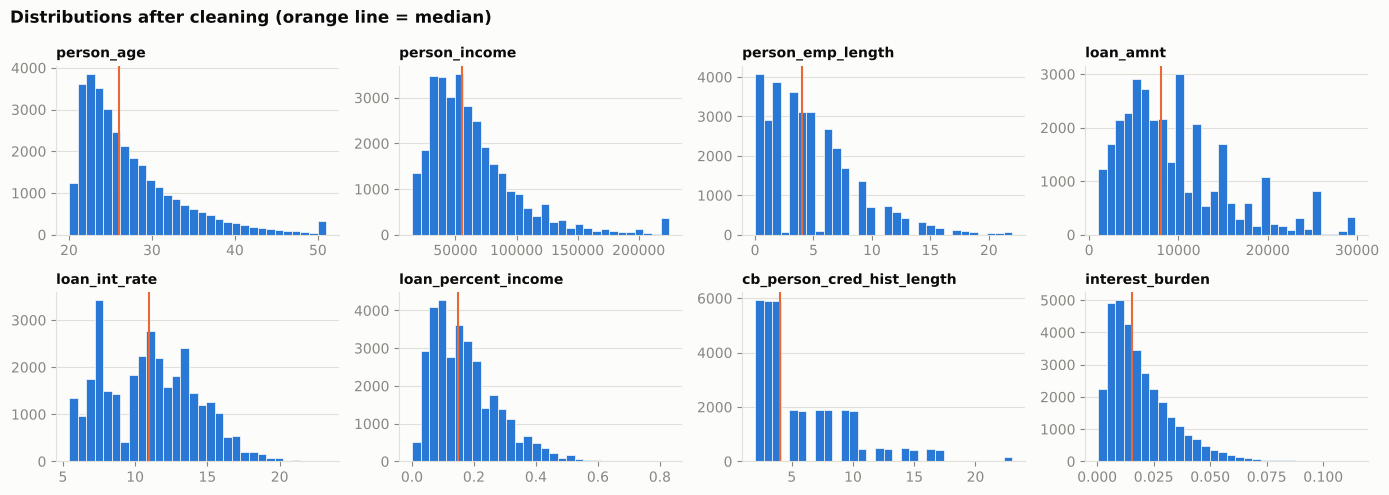

,count,mean,std,min,25%,50%,75%,max
person_age,32411.0,27.68,5.95,20.00,23.00,26.00,30.00,51.00
person_income,32411.0,64371.01,37731.01,14400.00,38500.00,55000.00,79200.00,225000.00
person_emp_length,32411.0,4.76,3.95,0.00,2.00,4.00,7.00,22.00
loan_amnt,32411.0,9560.69,6202.79,1000.00,5000.00,8000.00,12250.00,29800.00
loan_int_rate,32411.0,11.02,3.21,5.42,7.88,10.99,13.48,23.22
loan_percent_income,32411.0,0.17,0.11,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32411.0,5.79,3.97,2.00,3.00,4.00,8.00,23.00
interest_burden,32411.0,0.02,0.01,0.00,0.01,0.02,0.03,0.11


In [24]:
num_eda = ["person_age", "person_income", "person_emp_length", "loan_amnt",
           "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length", "interest_burden"]
fig, axes = plt.subplots(2, 4, figsize=(14, 5))
for ax, c in zip(axes.ravel(), num_eda):
    ax.hist(df[c], bins=30, color=C["blue"], edgecolor=SURFACE, linewidth=0.5)
    ax.axvline(df[c].median(), color=C["orange"], lw=1.5)
    ax.set_title(f"{c}", fontsize=10)
    ax.grid(axis="x", visible=False)
fig.suptitle("Distributions after cleaning (orange line = median)", x=0.01, ha="left", fontsize=12, fontweight="bold")
savefig("08_numeric_distributions")
df[num_eda].describe().T.round(2)

### 5.3 Categorical variables: default rate by group

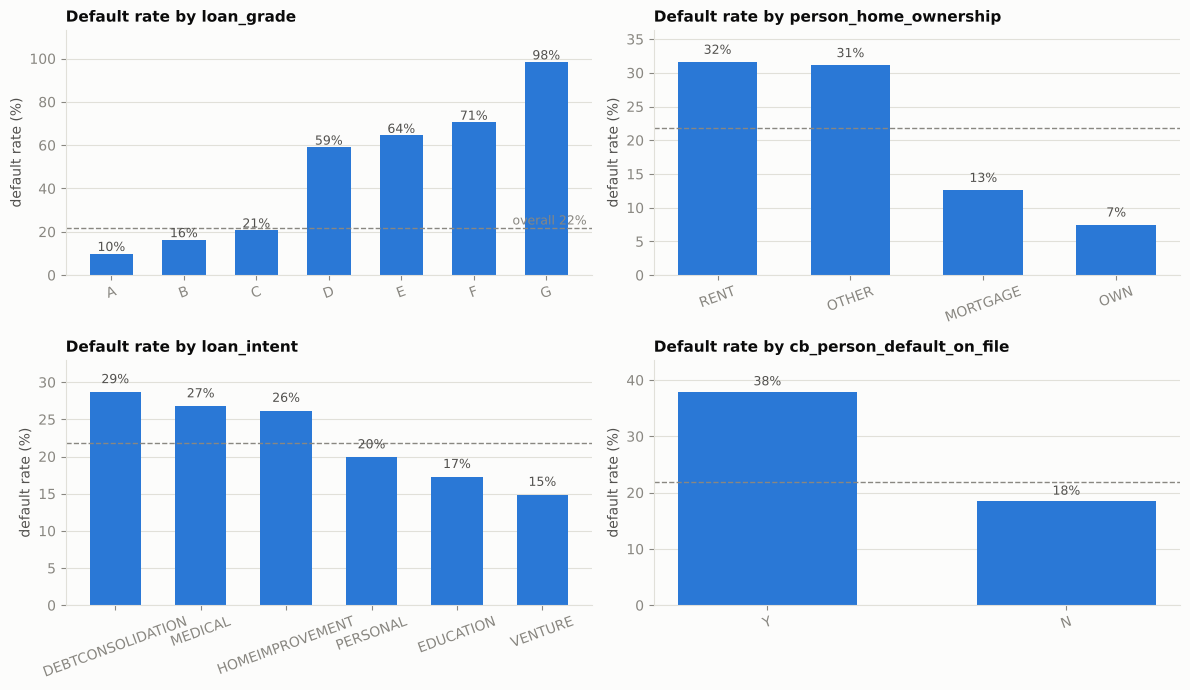

In [25]:
cat_plot = ["loan_grade", "person_home_ownership", "loan_intent", "cb_person_default_on_file"]
overall = df.loan_status.mean()
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, c in zip(axes.ravel(), cat_plot):
    g = df.groupby(c)["loan_status"].agg(["mean", "size"])
    if c != "loan_grade":
        g = g.sort_values("mean", ascending=False)
    bars = ax.bar(g.index.astype(str), g["mean"] * 100, color=C["blue"], width=0.6)
    ax.axhline(overall * 100, color=MUTED, ls="--", lw=1)
    for b, m, n in zip(bars, g["mean"], g["size"]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1.2, f"{m * 100:.0f}%",
                ha="center", fontsize=9, color=INK2)
    ax.set_title(f"Default rate by {c}")
    ax.set_ylabel("default rate (%)")
    ax.set_ylim(0, max(g["mean"].max() * 100 * 1.15, overall * 100 * 1.3))
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="x", visible=False)
axes[0, 0].text(0.99, overall * 100 + 1.5, f"overall {overall:.0%}", transform=axes[0, 0].get_yaxis_transform(),
                ha="right", color=MUTED, fontsize=9)
savefig("09_default_rate_categorical")

### 5.4 Numeric variables vs the target

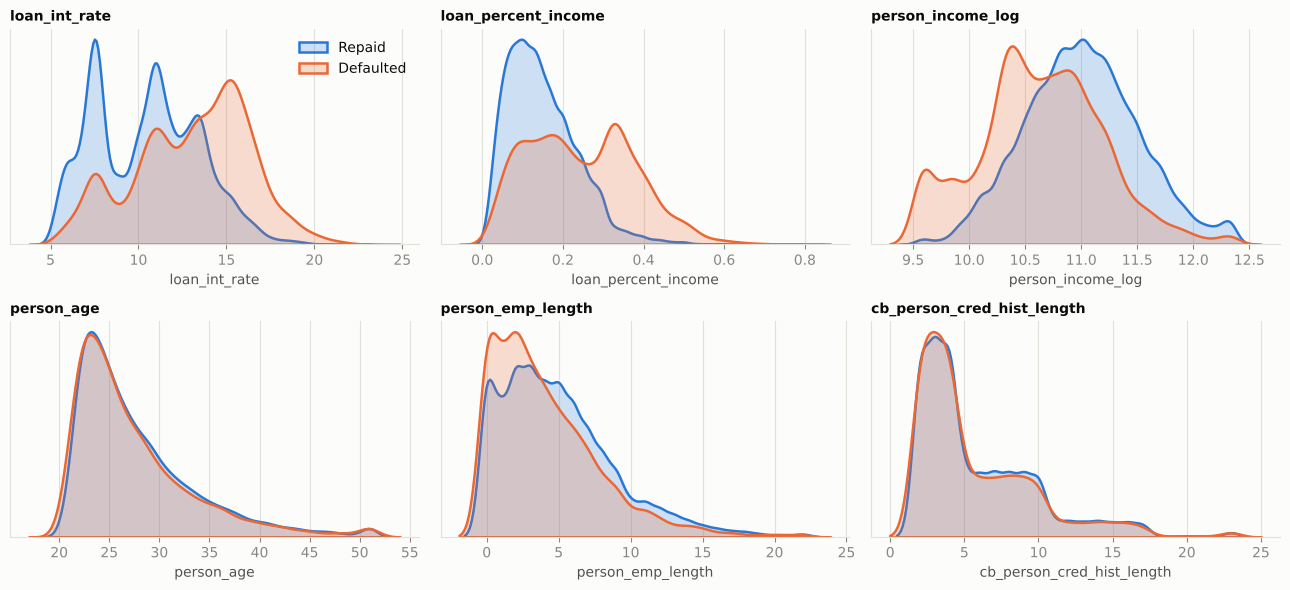

In [26]:
kde_cols = ["loan_int_rate", "loan_percent_income", "person_income_log",
            "person_age", "person_emp_length", "cb_person_cred_hist_length"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, c in zip(axes.ravel(), kde_cols):
    for cls, lab in [(0, "Repaid"), (1, "Defaulted")]:
        sns.kdeplot(df.loc[df.loan_status == cls, c], ax=ax, color=CLASS_COLORS[cls], fill=True,
                    alpha=0.22, linewidth=1.8, label=lab, common_norm=False)
    ax.set_title(c, fontsize=10)
    ax.set_ylabel("")
    ax.set_yticks([])
axes[0, 0].legend()
savefig("10_numeric_vs_target")

### 5.5 Default rate across business bands

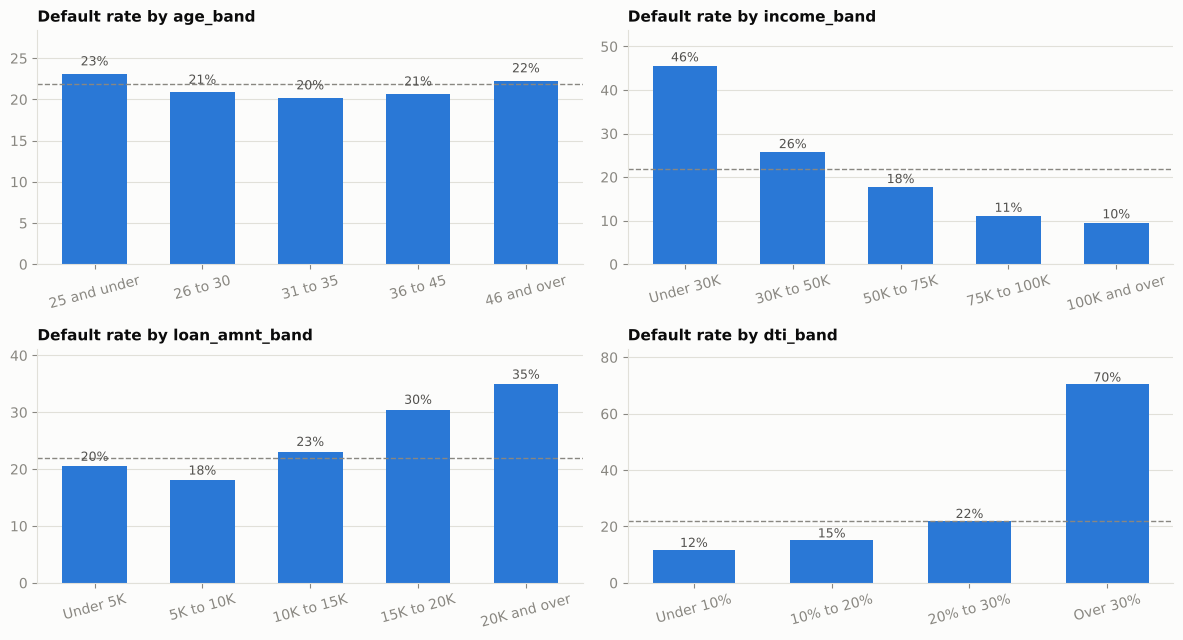

In [27]:
band_specs = [("age_band", ["25 and under", "26 to 30", "31 to 35", "36 to 45", "46 and over"]),
              ("income_band", ["Under 30K", "30K to 50K", "50K to 75K", "75K to 100K", "100K and over"]),
              ("loan_amnt_band", ["Under 5K", "5K to 10K", "10K to 15K", "15K to 20K", "20K and over"]),
              ("dti_band", ["Under 10%", "10% to 20%", "20% to 30%", "Over 30%"])]
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5))
for ax, (b, order) in zip(axes.ravel(), band_specs):
    g = df.groupby(b)["loan_status"].mean().reindex(order) * 100
    bars = ax.bar(g.index, g.values, color=C["blue"], width=0.6)
    ax.axhline(overall * 100, color=MUTED, ls="--", lw=1)
    for bar, v in zip(bars, g.values):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 1, f"{v:.0f}%", ha="center", fontsize=9, color=INK2)
    ax.set_title(f"Default rate by {b}")
    ax.set_ylim(0, max(g.max() * 1.18, overall * 130))
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="x", visible=False)
savefig("11_default_rate_bands")

### 5.6 Correlation (Spearman, which is robust to skew and outliers)

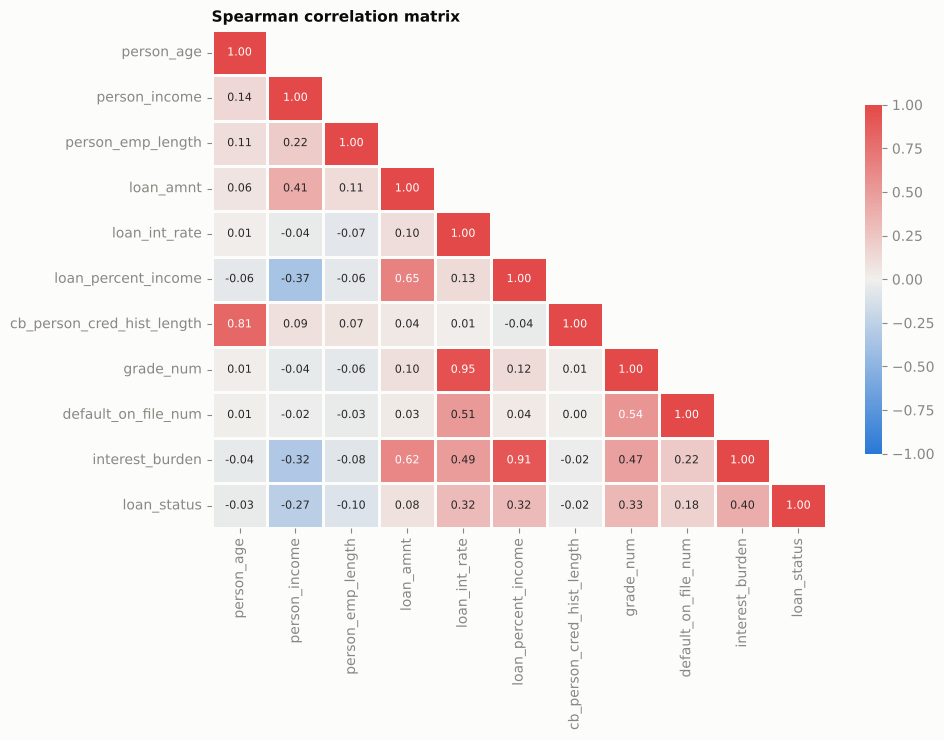

Strongly related feature pairs (|r| >= 0.6), a hint about multicollinearity:


,feature_a,feature_b,r
81,grade_num,loan_int_rate,0.95
104,interest_burden,loan_percent_income,0.91
66,cb_person_cred_hist_length,person_age,0.81
58,loan_percent_income,loan_amnt,0.65
102,interest_burden,loan_amnt,0.62


In [28]:
corr_cols = ["person_age", "person_income", "person_emp_length", "loan_amnt", "loan_int_rate",
             "loan_percent_income", "cb_person_cred_hist_length", "grade_num", "default_on_file_num",
             "interest_burden", "loan_status"]
corr = df[corr_cols].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(10, 7.5))
sns.heatmap(corr, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=1, linecolor=SURFACE, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Spearman correlation matrix")
ax.grid(False)
savefig("12_correlation_heatmap")

pairs = (corr.where(~mask & (corr != 1)).stack().rename("r").reset_index()
         .rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
print("Strongly related feature pairs (|r| >= 0.6), a hint about multicollinearity:")
pairs[pairs.r.abs() >= 0.6].sort_values("r", key=abs, ascending=False).round(2)

### 5.7 Statistical tests: which variables really differ between defaulters and non-defaulters?

- **Numeric variables**: Mann-Whitney U test (no normality assumption) plus an effect size (*rank-biserial*, from -1 to 1;
  positive means defaulters tend to have larger values).
- **Categorical variables**: chi-square test of independence plus **Cramer's V** (0 = unrelated, 1 = perfectly related).

In [29]:
rows = []
for c in ["loan_int_rate", "loan_percent_income", "interest_burden", "person_income", "loan_amnt",
          "person_age", "person_emp_length", "cb_person_cred_hist_length", "grade_num"]:
    a = df.loc[df.loan_status == 1, c]; b = df.loc[df.loan_status == 0, c]
    u, p = stats.mannwhitneyu(a, b)
    rows.append({"variable": c, "median_defaulted": round(a.median(), 3), "median_repaid": round(b.median(), 3),
                 "p_value": p, "effect_size_r": round(2 * u / (len(a) * len(b)) - 1, 3)})
num_tests = pd.DataFrame(rows).set_index("variable").sort_values("effect_size_r", key=abs, ascending=False)
display(num_tests)

rows = []
for c in ["loan_grade", "person_home_ownership", "loan_intent", "cb_person_default_on_file", "age_band"]:
    ct = pd.crosstab(df[c], df.loan_status)
    chi2, p, _, _ = stats.chi2_contingency(ct)
    rows.append({"variable": c, "chi2": round(chi2, 1), "p_value": p,
                 "cramers_v": round(np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))), 3)})
cat_tests = pd.DataFrame(rows).set_index("variable").sort_values("cramers_v", ascending=False)
display(cat_tests)

,median_defaulted,median_repaid,p_value,effect_size_r
variable,,,,
interest_burden,0.029,0.013,0.000000e+00,0.552
grade_num,3.000,2.000,0.000000e+00,0.447
loan_int_rate,13.480,10.650,0.000000e+00,0.445
loan_percent_income,0.240,0.130,0.000000e+00,0.442
person_income,41682.000,60000.000,0.000000e+00,-0.380
person_emp_length,3.000,4.000,7.461872e-73,-0.139
loan_amnt,9600.000,8000.000,3.014595e-52,0.118
person_age,26.000,26.000,4.908089e-10,-0.048
cb_person_cred_hist_length,4.000,4.000,6.872145e-06,-0.035


,chi2,p_value,cramers_v
variable,,,
loan_grade,5587.3,0.000000e+00,0.415
person_home_ownership,1894.7,0.000000e+00,0.242
cb_person_default_on_file,1041.5,1.754069e-228,0.179
loan_intent,519.6,4.777552e-110,0.127
age_band,28.6,9.389346e-06,0.030


### 5.8 Key EDA findings (computed from the data)

In [30]:
g = df.groupby("loan_grade")["loan_status"].mean()
h = df.groupby("person_home_ownership")["loan_status"].mean()
i = df.groupby("loan_intent")["loan_status"].mean()
d = df.groupby("cb_person_default_on_file")["loan_status"].mean()
dti = df.groupby("dti_band")["loan_status"].mean()
print(f"1. Lender grade is a strong signal: grade A defaults {g['A']:.0%}, grade D {g['D']:.0%}, grade G {g['G']:.0%}.")
print(f"2. Home ownership: renters default {h['RENT']:.0%}, mortgage holders {h['MORTGAGE']:.0%}, owners {h['OWN']:.0%}.")
print(f"3. Loan purpose: highest default rate is {i.idxmax()} ({i.max():.0%}); lowest is {i.idxmin()} ({i.min():.0%}).")
print(f"4. A past default on file raises default risk from {d['N']:.0%} to {d['Y']:.0%}.")
print(f"5. Loan burden matters: loans above 30% of income default {dti['Over 30%']:.0%} vs {dti['Under 10%']:.0%} for loans under 10%.")
print(f"6. Interest rate: defaulters pay a median {df.loc[df.loan_status==1,'loan_int_rate'].median():.1f}% "
      f"vs {df.loc[df.loan_status==0,'loan_int_rate'].median():.1f}% for people who repay.")
print(f"7. Employment-length values that were missing defaulted at {df.loc[df.emp_length_missing==1,'loan_status'].mean():.0%} "
      f"vs {df.loc[df.emp_length_missing==0,'loan_status'].mean():.0%} otherwise.")

1. Lender grade is a strong signal: grade A defaults 10%, grade D 59%, grade G 98%.
2. Home ownership: renters default 32%, mortgage holders 13%, owners 7%.
3. Loan purpose: highest default rate is DEBTCONSOLIDATION (29%); lowest is VENTURE (15%).
4. A past default on file raises default risk from 18% to 38%.
5. Loan burden matters: loans above 30% of income default 70% vs 12% for loans under 10%.
6. Interest rate: defaulters pay a median 13.5% vs 10.7% for people who repay.
7. Employment-length values that were missing defaulted at 32% vs 22% otherwise.


## 6. Customer segmentation (unsupervised ML)

**K-Means** groups customers who look alike *without being told the outcome*. The bank can then treat each group differently
(pricing, limits, marketing, monitoring). We use nine customer and loan characteristics, standardized so no variable dominates.

**Choosing k.** The *elbow* plot (inertia) and the *silhouette score* (how well separated the groups are) guide the choice.
We search 3 to 6 segments, because fewer is too coarse for a bank and more is hard to act on.

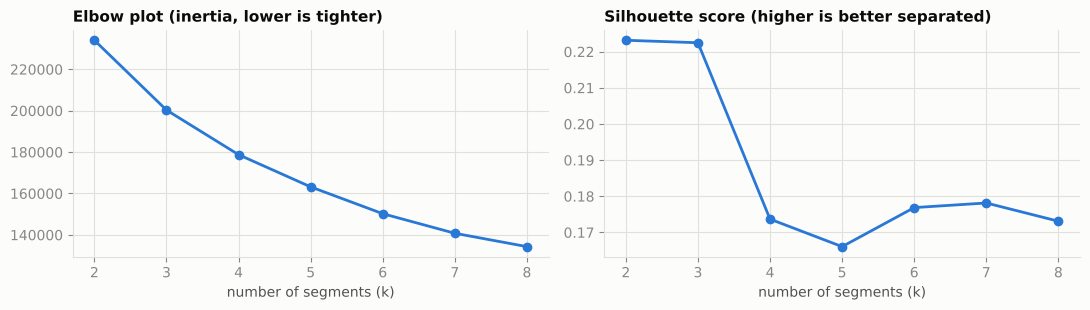

{2: 0.223, 3: 0.222, 4: 0.174, 5: 0.166, 6: 0.177, 7: 0.178, 8: 0.173}
Chosen k = 3 (best silhouette in the 3-6 range)


In [31]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

seg_features = ["person_age", "person_income_log", "person_emp_length", "loan_amnt_log", "loan_int_rate",
                "loan_percent_income", "cb_person_cred_hist_length", "grade_num", "default_on_file_num"]
Xseg = StandardScaler().fit_transform(df[seg_features])

inertia, sil = {}, {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xseg)
    inertia[k] = km.inertia_
    sil[k] = silhouette_score(Xseg, km.labels_, sample_size=6000, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].plot(list(inertia), list(inertia.values()), marker="o", color=C["blue"], lw=2)
axes[0].set_title("Elbow plot (inertia, lower is tighter)"); axes[0].set_xlabel("number of segments (k)")
axes[1].plot(list(sil), list(sil.values()), marker="o", color=C["blue"], lw=2)
axes[1].set_title("Silhouette score (higher is better separated)"); axes[1].set_xlabel("number of segments (k)")
savefig("13_choose_k")

best_k = max(range(3, 7), key=lambda k: sil[k])
print({k: round(v, 3) for k, v in sil.items()})
print(f"Chosen k = {best_k} (best silhouette in the 3-6 range)")

In [32]:
km = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit(Xseg)
df["segment_id"] = km.labels_ + 1

SEGMENT_NAMES = {i: f"Segment {i}" for i in sorted(df.segment_id.unique())}
df["segment"] = df.segment_id.map(SEGMENT_NAMES)

profile = df.groupby("segment_id").agg(
    customers=("segment_id", "size"),
    avg_age=("person_age", "mean"),
    median_income=("person_income", "median"),
    avg_loan=("loan_amnt", "mean"),
    avg_int_rate=("loan_int_rate", "mean"),
    avg_loan_pct_income=("loan_percent_income", "mean"),
    avg_cred_history=("cb_person_cred_hist_length", "mean"),
    avg_grade=("grade_num", "mean"),
    prior_default_share=("default_on_file_num", "mean"),
    default_rate=("loan_status", "mean"),
)
profile.insert(1, "share_%", (profile.customers / len(df) * 100).round(1))
profile.round(2)

,customers,share_%,avg_age,median_income,avg_loan,avg_int_rate,avg_loan_pct_income,avg_cred_history,avg_grade,prior_default_share,default_rate
segment_id,,,,,,,,,,,
1,18351,56.6,25.31,53155.0,8707.87,9.48,0.17,4.21,1.62,0.00,0.14
2,5909,18.2,36.64,69000.0,10716.29,10.48,0.15,11.76,1.98,0.07,0.14
3,8151,25.1,26.51,53000.0,10642.97,14.88,0.19,5.03,3.74,0.65,0.45


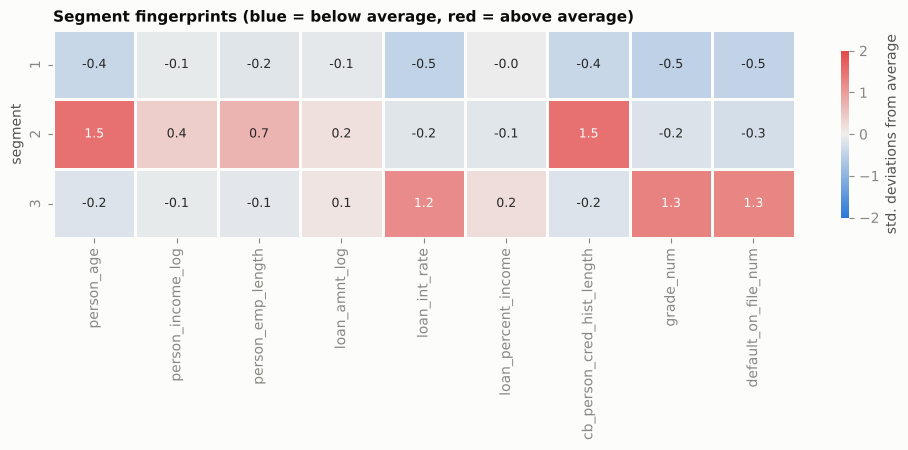

In [33]:
# Segment "fingerprints": how far each segment is from the average customer (in standard deviations)
z = pd.DataFrame(Xseg, columns=seg_features).groupby(df.segment_id.values).mean()
fig, ax = plt.subplots(figsize=(10, 0.7 * best_k + 2.5))
sns.heatmap(z, cmap=DIVERGING, center=0, vmin=-2, vmax=2, annot=True, fmt=".1f", annot_kws={"size": 9},
            linewidths=1, linecolor=SURFACE, cbar_kws={"shrink": 0.8, "label": "std. deviations from average"}, ax=ax)
ax.set_title("Segment fingerprints (blue = below average, red = above average)")
ax.set_ylabel("segment"); ax.grid(False)
savefig("14_segment_fingerprints")

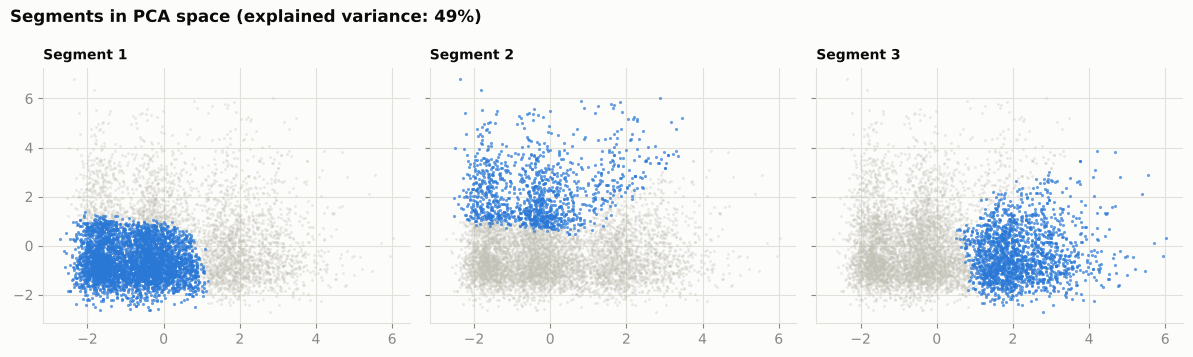

In [34]:
# Where the segments sit: project to 2 dimensions with PCA, one panel per segment
pca = PCA(n_components=2, random_state=RANDOM_STATE)
P = pca.fit_transform(Xseg)
rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(len(df), size=7000, replace=False)
ncols = 3
nrows = int(np.ceil(best_k / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.6 * nrows), sharex=True, sharey=True)
for ax, sid in zip(axes.ravel(), sorted(df.segment_id.unique())):
    sel = df.segment_id.values[idx] == sid
    ax.scatter(P[idx][~sel, 0], P[idx][~sel, 1], s=4, color=NEUTRAL, alpha=0.35, linewidths=0)
    ax.scatter(P[idx][sel, 0], P[idx][sel, 1], s=5, color=C["blue"], alpha=0.7, linewidths=0)
    ax.set_title(f"Segment {sid}", fontsize=10)
for ax in axes.ravel()[best_k:]:
    ax.axis("off")
fig.suptitle(f"Segments in PCA space (explained variance: {pca.explained_variance_ratio_.sum():.0%})",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
savefig("15_segments_pca")

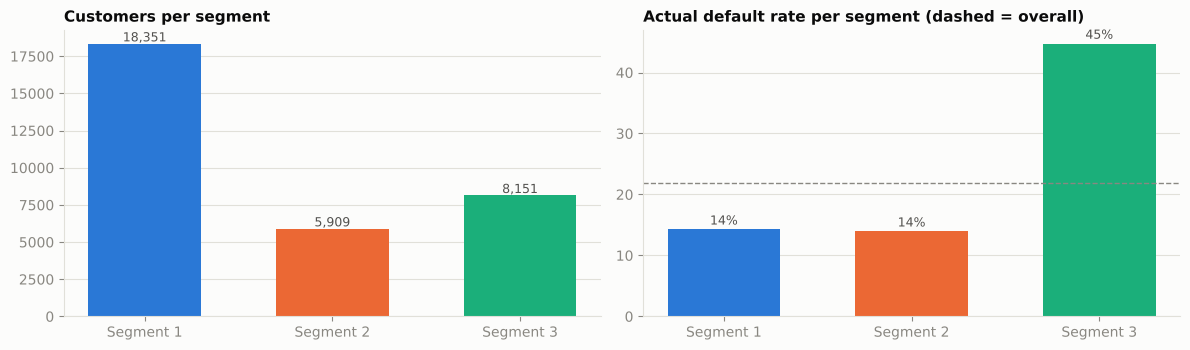

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
order = sorted(df.segment_id.unique())
seg_colors = [list(C.values())[i] for i in range(len(order))]
sizes = profile.loc[order, "customers"]
bars = axes[0].bar([f"Segment {i}" for i in order], sizes, color=seg_colors, width=0.6)
for b, v in zip(bars, sizes):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 150, f"{v:,}", ha="center", fontsize=9, color=INK2)
axes[0].set_title("Customers per segment"); axes[0].grid(axis="x", visible=False)
rates = profile.loc[order, "default_rate"] * 100
bars = axes[1].bar([f"Segment {i}" for i in order], rates, color=seg_colors, width=0.6)
axes[1].axhline(overall * 100, color=MUTED, ls="--", lw=1)
for b, v in zip(bars, rates):
    axes[1].text(b.get_x() + b.get_width() / 2, v + 0.8, f"{v:.0f}%", ha="center", fontsize=9, color=INK2)
axes[1].set_title("Actual default rate per segment (dashed = overall)"); axes[1].grid(axis="x", visible=False)
savefig("16_segment_size_and_risk")

### Segment names and what they mean

The fingerprints above show what is special about each group, and the business names below are assigned from them.

| Segment | Who they are | Business reading |
|---|---|---|
| **1. Young Prime Borrowers** | Youngest group (about 25), best lender grades, no prior defaults, short credit history, smaller loans | Largest group (over half of customers) with below-average default rate. Good target for growth and cross-selling. |
| **2. Established Borrowers** | Oldest group (about 37), very long credit history (about 12 years), highest income, good grades | Stable and low risk. Good candidates for larger limits and loyalty offers. |
| **3. High-Risk Borrowers** | Weakest grades, highest interest rates, most prior defaults, heaviest loan burden | Default rate roughly three times higher than the other segments. Needs tighter limits, risk-based pricing and early monitoring. |

*Note on cluster quality:* the silhouette score is modest (about 0.22). Customers form a continuum rather than sharply separated islands,
which is normal for credit data. The segments are still useful because they differ strongly in the outcome that matters (default rate),
even though the outcome was **not** used to build them.

In [36]:
SEGMENT_NAMES = {1: "Young Prime Borrowers", 2: "Established Borrowers", 3: "High-Risk Borrowers"}
# safety check: the names only make sense if the cluster ids still match their profiles
assert best_k == 3 and profile.default_rate.idxmax() == 3 and profile.avg_age.idxmax() == 2 and profile.avg_age.idxmin() == 1
df["segment"] = df.segment_id.map(SEGMENT_NAMES)
segment_summary = profile.reset_index()
segment_summary.insert(1, "segment", segment_summary.segment_id.map(SEGMENT_NAMES))
segment_summary.round(3)

,segment_id,segment,customers,share_%,avg_age,median_income,avg_loan,avg_int_rate,avg_loan_pct_income,avg_cred_history,avg_grade,prior_default_share,default_rate
0,1,Young Prime Borrowers,18351,56.6,25.309,53155.0,8707.874,9.478,0.165,4.213,1.623,0.000,0.143
1,2,Established Borrowers,5909,18.2,36.637,69000.0,10716.289,10.480,0.155,11.757,1.982,0.067,0.139
2,3,High-Risk Borrowers,8151,25.1,26.512,53000.0,10642.973,14.883,0.193,5.029,3.739,0.654,0.447


## 7. Loan default prediction (supervised ML)

**Question:** given what we know about an applicant, what is the probability that the loan defaults?

The workflow, in order:
1. Split into **train (80%)** and **test (20%)** *before* anything that learns from the data.
2. Put scaling and encoding **inside a pipeline**, so each cross-validation fold learns them only from its own training part.
3. Test ways to handle the **22% / 78% class imbalance**.
4. Compare three models with **5-fold stratified cross-validation**.
5. **Tune** the best one, then judge it **once** on the untouched test set.
6. Pick a **decision threshold** from business costs and explain predictions with **SHAP**.

In [37]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             accuracy_score, confusion_matrix, roc_curve, precision_recall_curve)
from sklearn.calibration import calibration_curve
from sklearn.base import clone
from xgboost import XGBClassifier
import xgboost

num_cols = ["person_age", "person_income_log", "person_emp_length", "loan_amnt_log", "loan_int_rate",
            "loan_percent_income", "cb_person_cred_hist_length", "interest_burden", "cred_hist_to_age", "emp_to_age"]
flag_cols = ["grade_num", "default_on_file_num", "emp_length_missing"]
cat_cols = ["person_home_ownership", "loan_intent"]

X = df[num_cols + flag_cols + cat_cols]
y = df["loan_status"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {len(X_train):,} rows ({y_train.mean():.1%} default)   Test: {len(X_test):,} rows ({y_test.mean():.1%} default)")

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("flag", "passthrough", flag_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1", "recall": "recall", "precision": "precision"}
neg, pos = int((y_train == 0).sum()), int((y_train == 1).sum())

Train: 25,928 rows (21.9% default)   Test: 6,483 rows (21.9% default)


### 7.1 Handling class imbalance

Only 22% of loans default, so a lazy model that says "nobody will default" is already 78% accurate and useless.
We compare four strategies with the same model (XGBoost), all inside cross-validation so resampling only touches the training folds:

1. **Nothing**: the baseline.
2. **Class weights**: errors on defaulters count about 3.6x more.
3. **SMOTE**: create synthetic defaulters by interpolating between real ones (oversampling).
4. **Random undersampling**: throw away some repaid loans to balance the classes.

In [38]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

def make_xgb(**kw):
    return XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=5, subsample=0.8, colsample_bytree=0.8,
                         eval_metric="logloss", n_jobs=2, random_state=RANDOM_STATE, **kw)

strategies = {
    "No handling": ImbPipeline([("prep", preprocess), ("model", make_xgb())]),
    "Class weights": ImbPipeline([("prep", preprocess), ("model", make_xgb(scale_pos_weight=neg / pos))]),
    "SMOTE oversampling": ImbPipeline([("prep", preprocess), ("smote", SMOTE(random_state=RANDOM_STATE)), ("model", make_xgb())]),
    "Random undersampling": ImbPipeline([("prep", preprocess), ("under", RandomUnderSampler(random_state=RANDOM_STATE)), ("model", make_xgb())]),
}
rows = {}
for name, pipe in strategies.items():
    res = cross_validate(pipe, X_train, y_train, cv=skf, scoring=scoring, n_jobs=1)
    rows[name] = {m: res[f"test_{m}"].mean() for m in scoring}
imb = pd.DataFrame(rows).T.round(3)
imb

,roc_auc,pr_auc,f1,recall,precision
No handling,0.948,0.904,0.833,0.731,0.968
Class weights,0.946,0.901,0.802,0.788,0.816
SMOTE oversampling,0.940,0.893,0.828,0.726,0.965
Random undersampling,0.944,0.897,0.783,0.811,0.757


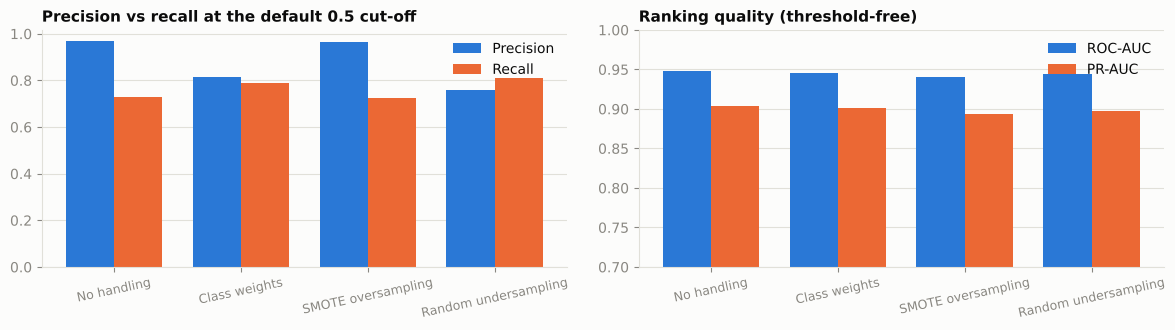

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
x = np.arange(len(imb)); w = 0.38
axes[0].bar(x - w / 2, imb["precision"], w, color=C["blue"], label="Precision")
axes[0].bar(x + w / 2, imb["recall"], w, color=C["orange"], label="Recall")
axes[0].set_xticks(x); axes[0].set_xticklabels(imb.index, rotation=12, fontsize=9)
axes[0].set_title("Precision vs recall at the default 0.5 cut-off"); axes[0].legend(); axes[0].grid(axis="x", visible=False)
axes[1].bar(x - w / 2, imb["roc_auc"], w, color=C["blue"], label="ROC-AUC")
axes[1].bar(x + w / 2, imb["pr_auc"], w, color=C["orange"], label="PR-AUC")
axes[1].set_ylim(0.7, 1.0)
axes[1].set_xticks(x); axes[1].set_xticklabels(imb.index, rotation=12, fontsize=9)
axes[1].set_title("Ranking quality (threshold-free)"); axes[1].legend(); axes[1].grid(axis="x", visible=False)
savefig("17_imbalance_strategies")

**What this shows**

- Resampling and class weights **trade precision for recall at the 0.5 cut-off**: more defaulters are caught, but more good customers are flagged.
- The **threshold-free ranking quality (ROC-AUC / PR-AUC) barely moves**: the model is equally good at *ordering* customers by risk.
- That means imbalance handling mostly **moves the decision threshold**. We prefer to keep the model's native, well-calibrated probabilities
  (needed for the Power BI risk bands) and choose the cut-off from **business costs** in 7.6. Resampling changes the probabilities themselves
  and makes them overestimate risk.

### 7.2 Baseline comparison: three models, 5-fold cross-validation

| Model | Idea |
|---|---|
| **Logistic Regression** | Simple, transparent linear baseline |
| **Random Forest** | Many decision trees voting, captures non-linear patterns |
| **XGBoost** | Trees built one after another, each fixing the previous errors; usually the strongest on tabular data |

In [40]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=250, min_samples_leaf=5, n_jobs=2, random_state=RANDOM_STATE),
    "XGBoost": make_xgb(),
}
cv_rows = {}
for name, m in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", m)])
    res = cross_validate(pipe, X_train, y_train, cv=skf, scoring=scoring, n_jobs=1)
    cv_rows[name] = {**{f"{k}_mean": res[f"test_{k}"].mean() for k in scoring},
                     "roc_auc_std": res["test_roc_auc"].std()}
cv_table = pd.DataFrame(cv_rows).T.round(4)
cv_table

,roc_auc_mean,pr_auc_mean,f1_mean,recall_mean,precision_mean,roc_auc_std
Logistic Regression,0.8743,0.7226,0.6264,0.5384,0.7494,0.0028
Random Forest,0.9291,0.8808,0.8174,0.7036,0.9753,0.0030
XGBoost,0.9478,0.9036,0.8327,0.7306,0.9680,0.0030


### 7.3 Hyperparameter tuning (XGBoost)

Hyperparameters are the settings of a model (tree depth, learning rate, ...). **Randomized search** tries 15 random combinations,
each scored with 3-fold cross-validation on the training data, optimizing PR-AUC (the stricter metric for imbalanced data).

In [41]:
from scipy.stats import randint, uniform, loguniform

base_pipe = Pipeline([("prep", preprocess),
                      ("model", XGBClassifier(eval_metric="logloss", n_jobs=2, random_state=RANDOM_STATE))])
param_dist = {
    "model__n_estimators": randint(150, 500),
    "model__max_depth": randint(3, 8),
    "model__learning_rate": loguniform(0.02, 0.2),
    "model__subsample": uniform(0.6, 0.4),
    "model__colsample_bytree": uniform(0.6, 0.4),
    "model__min_child_weight": randint(1, 11),
    "model__gamma": uniform(0, 2),
    "model__reg_lambda": loguniform(0.5, 10),
}
search = RandomizedSearchCV(base_pipe, param_dist, n_iter=15, scoring="average_precision",
                            cv=3, random_state=RANDOM_STATE, n_jobs=1, verbose=1, refit=True)
search.fit(X_train, y_train)
best_pipe = search.best_estimator_
print("Best CV PR-AUC:", round(search.best_score_, 4))
pd.Series({k.replace("model__", ""): (round(v, 4) if isinstance(v, float) else v)
           for k, v in search.best_params_.items()}, name="best value").to_frame()

Fitting 3 folds for each of 15 candidates, totalling 45 fits


Best CV PR-AUC: 0.9026


,best value
colsample_bytree,0.7218
gamma,0.1953
learning_rate,0.0967
max_depth,6.0000
min_child_weight,7.0000
n_estimators,413.0000
reg_lambda,0.5543
subsample,0.9637


### 7.4 Final evaluation on the untouched test set

The test set was not used for any choice so far, so these numbers are an honest estimate of real-world performance.
Metrics at the standard 0.5 cut-off (the cost-based cut-off comes in 7.6).

In [42]:
fitted = {}
for name, m in models.items():
    fitted[name] = Pipeline([("prep", preprocess), ("model", m)]).fit(X_train, y_train)
fitted["XGBoost (tuned)"] = best_pipe

def evaluate(model, X_, y_, thr=0.5):
    p = model.predict_proba(X_)[:, 1]
    pred = (p >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(y_, p), "PR-AUC": average_precision_score(y_, p),
            "Accuracy": accuracy_score(y_, pred), "Precision": precision_score(y_, pred),
            "Recall": recall_score(y_, pred), "F1": f1_score(y_, pred)}

test_table = pd.DataFrame({n: evaluate(m, X_test, y_test) for n, m in fitted.items()}).T.round(4)
test_table

,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
Logistic Regression,0.8706,0.7228,0.8623,0.7561,0.5465,0.6345
Random Forest,0.9248,0.8779,0.9331,0.9814,0.7073,0.8221
XGBoost,0.9447,0.9022,0.9360,0.9648,0.7341,0.8338
XGBoost (tuned),0.9483,0.9058,0.9364,0.9556,0.7440,0.8366


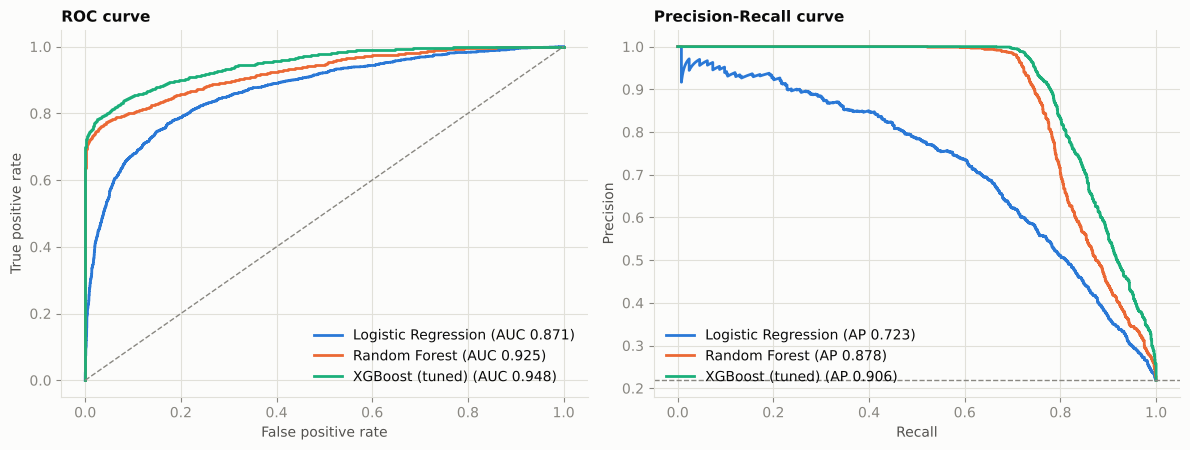

In [43]:
plot_models = {"Logistic Regression": C["blue"], "Random Forest": C["orange"], "XGBoost (tuned)": C["aqua"]}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
roc_points = []
for name, col in plot_models.items():
    p = fitted[name].predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=col, lw=2, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    axes[1].plot(rec, prec, color=col, lw=2, label=f"{name} (AP {average_precision_score(y_test, p):.3f})")
    roc_points.append(pd.DataFrame({"model": name, "fpr": fpr, "tpr": tpr}))
axes[0].plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1)
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].set_title("ROC curve")
axes[1].axhline(y_test.mean(), color=MUTED, ls="--", lw=1)
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-Recall curve")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "lower left")
savefig("18_roc_pr_curves")
roc_points = pd.concat(roc_points, ignore_index=True)

### 7.5 Is the probability trustworthy? (calibration)

If the model says "30% risk", about 30 out of 100 such customers should actually default. The dashboard uses these probabilities
directly, so we check it.

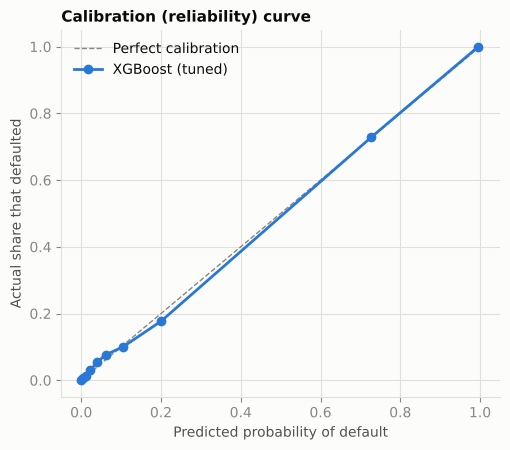

In [44]:
p_test = best_pipe.predict_proba(X_test)[:, 1]
frac_pos, mean_pred = calibration_curve(y_test, p_test, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1, label="Perfect calibration")
ax.plot(mean_pred, frac_pos, marker="o", color=C["blue"], lw=2, label="XGBoost (tuned)")
ax.set_xlabel("Predicted probability of default"); ax.set_ylabel("Actual share that defaulted")
ax.set_title("Calibration (reliability) curve"); ax.legend()
savefig("19_calibration")

### 7.6 Choosing the decision threshold from business costs

A model outputs a probability; the bank needs a decision (approve / review). A wrong call costs money either way:

- **False negative** (approve someone who defaults) - we lose the loan principal. Assumed cost = **5 units**.
- **False positive** (reject someone who would have repaid) - we lose the interest income. Assumed cost = **1 unit**.

(These 5:1 numbers are an *assumption* to be replaced with the bank's real figures.)
To avoid peeking at the test set, the threshold is chosen from **out-of-fold predictions on the training data**.

Cost-optimal threshold (FN=5, FP=1): 0.15
F1-optimal threshold for comparison: 0.56


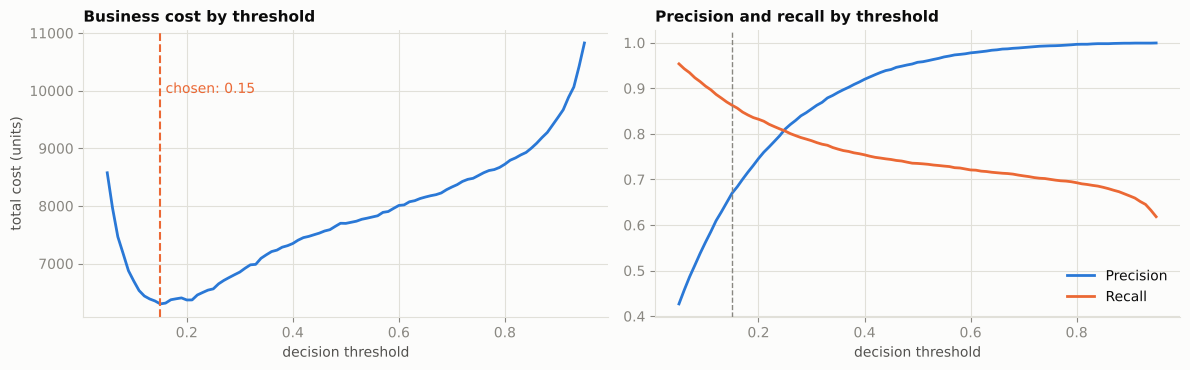

In [45]:
COST_FN, COST_FP = 5, 1
oof_train = cross_val_predict(clone(best_pipe), X_train, y_train, cv=skf, method="predict_proba")[:, 1]
thresholds = np.arange(0.05, 0.96, 0.01)
costs, f1s, precs, recs = [], [], [], []
for t in thresholds:
    pred = (oof_train >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    costs.append(COST_FN * fn + COST_FP * fp)
    f1s.append(f1_score(y_train, pred)); precs.append(precision_score(y_train, pred)); recs.append(recall_score(y_train, pred))
THR = float(thresholds[int(np.argmin(costs))])
print(f"Cost-optimal threshold (FN={COST_FN}, FP={COST_FP}): {THR:.2f}")
print(f"F1-optimal threshold for comparison: {thresholds[int(np.argmax(f1s))]:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(thresholds, costs, color=C["blue"], lw=2)
axes[0].axvline(THR, color=C["orange"], ls="--", lw=1.5)
axes[0].text(THR + 0.01, max(costs) * 0.92, f"chosen: {THR:.2f}", color=C["orange"])
axes[0].set_xlabel("decision threshold"); axes[0].set_ylabel("total cost (units)"); axes[0].set_title("Business cost by threshold")
axes[1].plot(thresholds, precs, color=C["blue"], lw=2, label="Precision")
axes[1].plot(thresholds, recs, color=C["orange"], lw=2, label="Recall")
axes[1].axvline(THR, color=MUTED, ls="--", lw=1)
axes[1].set_xlabel("decision threshold"); axes[1].set_title("Precision and recall by threshold"); axes[1].legend()
savefig("20_threshold_selection")

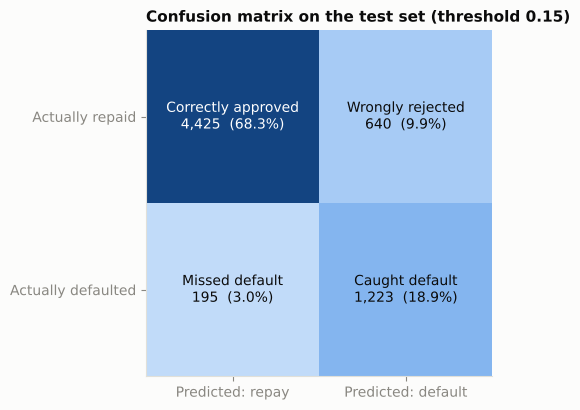

{'Precision': 0.656, 'Recall': 0.862, 'F1': 0.746, 'Accuracy': 0.871}
Business cost on the test set: tuned model at 0.15 = 1,615 units; approving everyone = 7,090 units


In [46]:
pred_test = (p_test >= THR).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred_test).ravel()
cm = np.array([[tn, fp], [fn, tp]])
fig, ax = plt.subplots(figsize=(5.2, 4.2))
ax.imshow(cm, cmap=SEQ_BLUE, vmin=0, vmax=cm.max() * 1.1)
labels = [["Correctly approved", "Wrongly rejected"], ["Missed default", "Caught default"]]
for i in range(2):
    for j in range(2):
        v = cm[i, j]
        ax.text(j, i, f"{labels[i][j]}\n{v:,}  ({v / cm.sum():.1%})", ha="center", va="center",
                color="white" if v > cm.max() * 0.5 else INK, fontsize=10)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Predicted: repay", "Predicted: default"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Actually repaid", "Actually defaulted"])
ax.set_title(f"Confusion matrix on the test set (threshold {THR:.2f})")
ax.grid(False)
savefig("21_confusion_matrix")

final_metrics = {"Precision": precision_score(y_test, pred_test), "Recall": recall_score(y_test, pred_test),
                 "F1": f1_score(y_test, pred_test), "Accuracy": accuracy_score(y_test, pred_test)}
print({k: round(v, 3) for k, v in final_metrics.items()})
print(f"Business cost on the test set: tuned model at {THR:.2f} = {COST_FN * fn + COST_FP * fp:,} units; "
      f"approving everyone = {COST_FN * int(y_test.sum()):,} units")

### 7.7 Explainability with SHAP

A bank must be able to say *why* a loan is risky. **SHAP** assigns each feature a contribution to every individual prediction
(positive pushes towards default, negative towards repayment). Averaging the absolute contributions gives global importance.

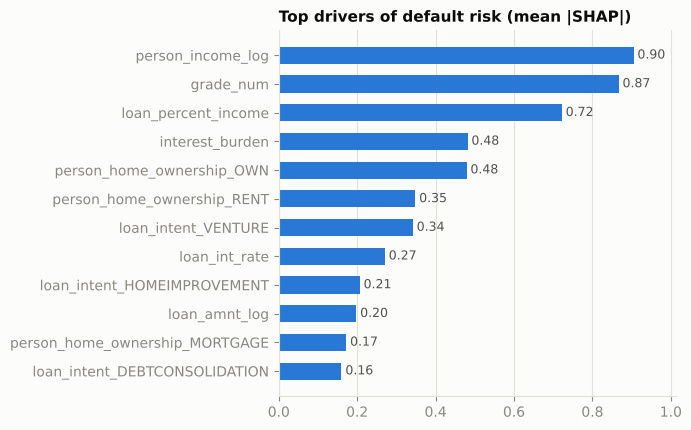

In [47]:
import shap

prep_fit = best_pipe.named_steps["prep"]
xgb_fit = best_pipe.named_steps["model"]
feat_names = [n.split("__", 1)[1] for n in prep_fit.get_feature_names_out()]

Xt_test = pd.DataFrame(prep_fit.transform(X_test), columns=feat_names, index=X_test.index)
sample = Xt_test.sample(2500, random_state=RANDOM_STATE)

# exact TreeSHAP values straight from XGBoost (log-odds scale)
contrib = xgb_fit.get_booster().predict(xgboost.DMatrix(sample.values), pred_contribs=True)
sv = shap.Explanation(values=contrib[:, :-1], base_values=contrib[:, -1], data=sample.values, feature_names=feat_names)

shap_importance = (pd.Series(np.abs(contrib[:, :-1]).mean(axis=0), index=feat_names, name="mean_abs_shap")
                   .sort_values(ascending=False))
top = shap_importance.head(12).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.barh(top.index, top.values, color=C["blue"], height=0.6)
for y_, v in enumerate(top.values):
    ax.text(v + 0.01, y_, f"{v:.2f}", va="center", fontsize=9, color=INK2)
ax.set_title("Top drivers of default risk (mean |SHAP|)"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, top.max() * 1.12)
savefig("22_shap_importance")

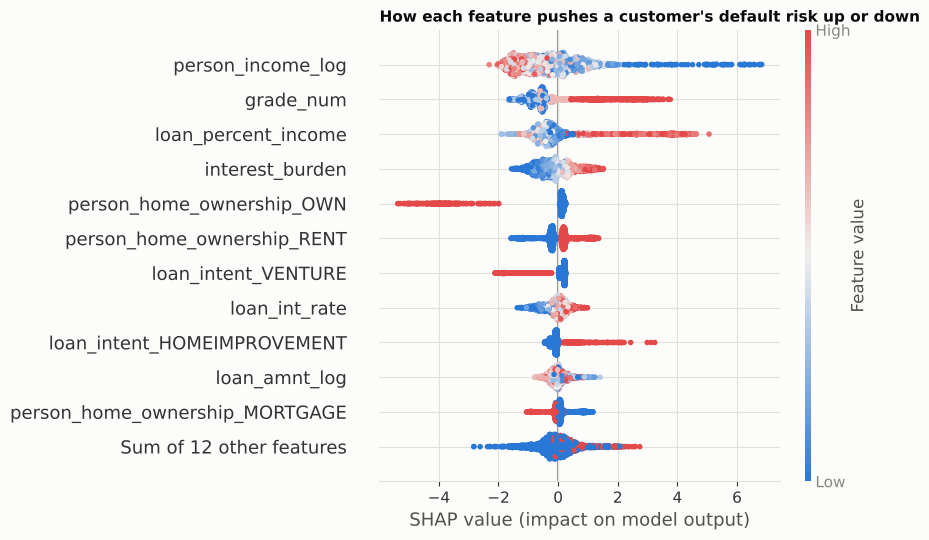

In [48]:
# Direction of effect: each dot is one customer; colour = feature value (blue low, red high)
try:
    shap.plots.beeswarm(sv, max_display=12, show=False, color=DIVERGING)
except Exception:
    shap.plots.beeswarm(sv, max_display=12, show=False)
plt.gcf().set_size_inches(9, 5.5)
plt.title("How each feature pushes a customer's default risk up or down")
savefig("23_shap_beeswarm")

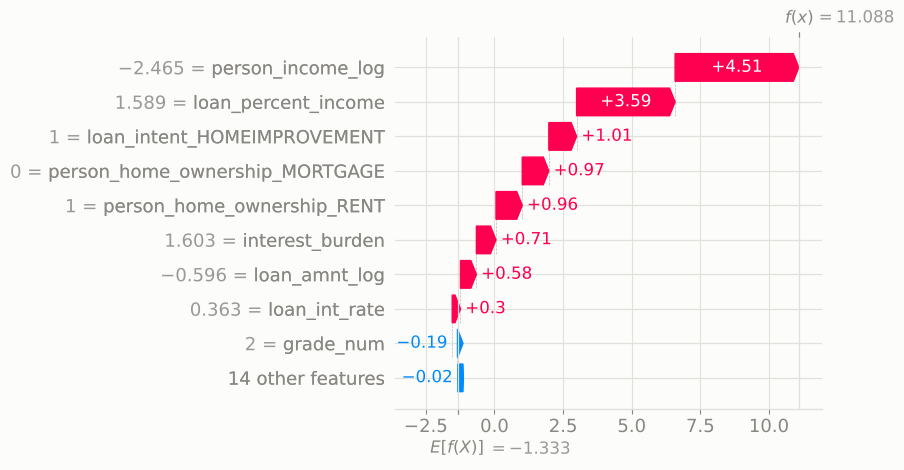

This customer: {'loan_int_rate': 12.18, 'loan_percent_income': 0.34, 'grade_num': 2, 'default_on_file_num': 0}


In [49]:
# One customer explained: the highest-risk customer in the sample
i = int(np.argmax(sv.values.sum(axis=1)))
shap.plots.waterfall(sv[i], max_display=10, show=False)
plt.gcf().set_size_inches(9, 4.8)
savefig("24_shap_one_customer")
orig = X_test.loc[sample.index[i]]
print("This customer:", orig[["loan_int_rate", "loan_percent_income", "grade_num", "default_on_file_num"]].to_dict())

## 8. Score every customer and export for Power BI

To give **every** customer an honest risk score, we use **out-of-fold predictions** on the full dataset: each customer is scored by a model
that never saw that customer during training. (Scoring training rows with a model trained on them would look unrealistically good.)

Risk bands turn the probability into something a dashboard can filter on.

In [50]:
oof_all = cross_val_predict(clone(best_pipe), X, y, cv=skf, method="predict_proba")[:, 1]

BAND_BINS = [0, 0.10, 0.40, 1.0001]
BAND_LABELS = ["Low", "Medium", "High"]
scored = df.copy()
scored.insert(0, "customer_id", np.arange(1, len(scored) + 1))
scored["default_probability"] = oof_all.round(4)
scored["risk_band"] = pd.cut(scored.default_probability, BAND_BINS, labels=BAND_LABELS, right=False).astype(str)
scored["predicted_default"] = (scored.default_probability >= THR).astype(int)
scored["prediction_outcome"] = np.select(
    [(scored.loan_status == 1) & (scored.predicted_default == 1), (scored.loan_status == 0) & (scored.predicted_default == 0),
     (scored.loan_status == 0) & (scored.predicted_default == 1)],
    ["Correct: default caught", "Correct: repaid approved", "Wrong: good customer rejected"],
    default="Wrong: default missed")

band_check = (scored.groupby("risk_band")
              .agg(customers=("customer_id", "size"), avg_predicted_risk=("default_probability", "mean"),
                   actual_default_rate=("loan_status", "mean"))
              .reindex(BAND_LABELS))
band_check["share_%"] = (band_check.customers / len(scored) * 100).round(1)
band_check.round(3)

,customers,avg_predicted_risk,actual_default_rate,share_%
risk_band,,,,
Low,20998,0.028,0.031,64.8
Medium,5616,0.191,0.190,17.3
High,5797,0.919,0.925,17.9


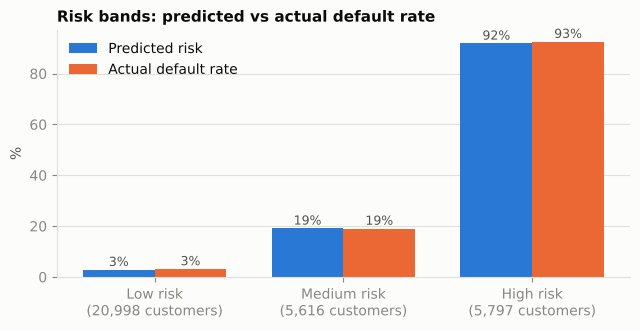

In [51]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
x = np.arange(3); w = 0.38
ax.bar(x - w / 2, band_check.avg_predicted_risk * 100, w, color=C["blue"], label="Predicted risk")
ax.bar(x + w / 2, band_check.actual_default_rate * 100, w, color=C["orange"], label="Actual default rate")
for xi, (a, b) in enumerate(zip(band_check.avg_predicted_risk, band_check.actual_default_rate)):
    ax.text(xi - w / 2, a * 100 + 1.5, f"{a:.0%}", ha="center", fontsize=9, color=INK2)
    ax.text(xi + w / 2, b * 100 + 1.5, f"{b:.0%}", ha="center", fontsize=9, color=INK2)
ax.set_xticks(x); ax.set_xticklabels([f"{b} risk\n({int(n):,} customers)" for b, n in zip(BAND_LABELS, band_check.customers)])
ax.set_ylabel("%"); ax.set_title("Risk bands: predicted vs actual default rate"); ax.legend(); ax.grid(axis="x", visible=False)
savefig("25_risk_bands")

In [52]:
export_cols = ["customer_id", "person_age", "age_band", "person_income", "income_band", "person_home_ownership",
               "person_emp_length", "loan_intent", "loan_grade", "loan_amnt", "loan_amnt_band", "loan_int_rate",
               "loan_percent_income", "dti_band", "cb_person_default_on_file", "cb_person_cred_hist_length",
               "interest_burden", "segment_id", "segment", "loan_status", "default_probability", "risk_band",
               "predicted_default", "prediction_outcome"]
scored[export_cols].to_csv("outputs/scored_customers.csv", index=False, encoding="utf-8-sig")

# model comparison table (one tidy table for the dashboard's model panel)
model_cmp = test_table.copy()
model_cmp.loc["XGBoost (tuned) @ cost threshold"] = [
    roc_auc_score(y_test, p_test), average_precision_score(y_test, p_test), final_metrics["Accuracy"],
    final_metrics["Precision"], final_metrics["Recall"], final_metrics["F1"]]
model_cmp.rename_axis("model").round(4).reset_index().to_csv("outputs/model_comparison.csv", index=False, encoding="utf-8-sig")

shap_importance.rename_axis("feature").reset_index().round(4).to_csv("outputs/feature_importance.csv", index=False, encoding="utf-8-sig")
roc_points.round(5).to_csv("outputs/roc_points.csv", index=False, encoding="utf-8-sig")

cm_long = pd.DataFrame([
    {"actual": "Repaid", "predicted": "Repay", "count": int(tn), "label": "Correctly approved"},
    {"actual": "Repaid", "predicted": "Default", "count": int(fp), "label": "Wrongly rejected"},
    {"actual": "Defaulted", "predicted": "Repay", "count": int(fn), "label": "Missed default"},
    {"actual": "Defaulted", "predicted": "Default", "count": int(tp), "label": "Caught default"}])
cm_long.to_csv("outputs/confusion_matrix.csv", index=False, encoding="utf-8-sig")

segment_summary.round(4).to_csv("outputs/segment_summary.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(prep_log).to_csv("outputs/preprocessing_log.csv", index=False, encoding="utf-8-sig")
df.to_csv("outputs/cleaned_dataset.csv", index=False, encoding="utf-8-sig")

import joblib
final_model = clone(best_pipe).fit(X, y)
joblib.dump(final_model, "outputs/default_model.joblib")

print("Exported to outputs/:")
for f in sorted(os.listdir("outputs")):
    if os.path.isfile(f"outputs/{f}"):
        print(f"  {f:30s} {os.path.getsize('outputs/' + f) / 1024:8.1f} KB")

Exported to outputs/:
  cleaned_dataset.csv              6827.5 KB
  confusion_matrix.csv                0.2 KB
  default_model.joblib              964.0 KB
  feature_importance.csv              0.6 KB
  model_comparison.csv                0.3 KB
  preprocessing_log.csv               1.1 KB
  roc_points.csv                     89.9 KB
  scored_customers.csv             5848.7 KB
  segment_summary.csv                 0.5 KB


## 9. Summary

In [53]:
print("DATA")
print(f"  {len(raw):,} raw rows -> {len(df):,} clean rows; 0 missing values left.")
print(f"  Fixed: {len(prep_log)} logged issues (see the preprocessing log above).")
print("SEGMENTATION")
print(f"  K-Means with k={best_k} (silhouette {sil[best_k]:.3f}).")
print("DEFAULT MODEL (test set)")
m = test_table.loc["XGBoost (tuned)"]
print(f"  Tuned XGBoost: ROC-AUC {m['ROC-AUC']:.3f}, PR-AUC {m['PR-AUC']:.3f}.")
print(f"  At the cost-based threshold {THR:.2f}: precision {final_metrics['Precision']:.2f}, recall {final_metrics['Recall']:.2f}, F1 {final_metrics['F1']:.2f}.")
print("RISK BANDS")
for b, r in band_check.iterrows():
    print(f"  {b:6s}: {int(r.customers):6,} customers, actual default rate {r.actual_default_rate:.1%}")
print("TOP DRIVERS (SHAP)")
for f_, v in shap_importance.head(5).items():
    print(f"  {f_:28s} {v:.2f}")

DATA
  32,580 raw rows -> 32,411 clean rows; 0 missing values left.
  Fixed: 12 logged issues (see the preprocessing log above).
SEGMENTATION
  K-Means with k=3 (silhouette 0.222).
DEFAULT MODEL (test set)
  Tuned XGBoost: ROC-AUC 0.948, PR-AUC 0.906.
  At the cost-based threshold 0.15: precision 0.66, recall 0.86, F1 0.75.
RISK BANDS
  Low   : 20,998 customers, actual default rate 3.1%
  Medium:  5,616 customers, actual default rate 19.0%
  High  :  5,797 customers, actual default rate 92.5%
TOP DRIVERS (SHAP)
  person_income_log            0.90
  grade_num                    0.87
  loan_percent_income          0.72
  interest_burden              0.48
  person_home_ownership_OWN    0.48


### Limitations and honest notes

- **`loan_grade` and `loan_int_rate` are set by the lender**, partly *using* risk assessment, so they carry much of the predictive power.
  In a real bank they may only be known *after* underwriting; a model for early screening would exclude them.
- The **5:1 cost ratio** is an assumption. The threshold should be recomputed with the bank's actual loss and margin numbers.
- The data is a **snapshot** of one lender, with no time dimension, so we cannot test how the model ages (drift).
- The model should be monitored for **fairness** across groups such as age and home ownership before any real use.
- Imputed values are estimates; the `emp_length_missing` flag keeps the information that they were missing.